# Pasqal / Pulser Simulation and Optimization Pipeline

**Stylianos Mikeos**  
IRIDA Research Centre for Communication Technologies, University of Cyprus  
Supervisor: Professor Dr. Ioannis Krikidis  
Final notebook — September 2026

This notebook documents a simulation-based study of the Pasqal/Pulser neutral-atom programming workflow. It progresses from basic pulse-level experiments to graph optimization, communication-inspired MIMO configuration selection, controlled noise sensitivity, graph-size scaling, and weighted maximum independent set (MWIS) optimization.

All quantum results in this notebook are simulator outputs. Small optimization instances are checked against exact classical benchmarks whenever possible. The notebook does not claim hardware benchmarking or quantum advantage.


<a id="top"></a>

## Notebook structure

<details open>
<summary><strong>Part 1 — Beginner Pulser Experiments</strong></summary>

<ul>
  <li><a href="#part-1">Part 1 overview</a></li>
  <li><a href="#p1-exp1">Experiment 1 — Single-atom π-pulse</a></li>
  <li><a href="#p1-exp2">Experiment 2 — Rabi oscillation scan</a></li>
  <li><a href="#p1-exp3">Experiment 3 — Two-atom Rydberg blockade</a></li>
  <li><a href="#p1-exp4">Experiment 4 — Three-atom chain</a></li>
  <li><a href="#p1-exp5">Experiment 5 — Distance scan and blockade strength</a></li>
  <li><a href="#p1-exp6">Experiment 6 — Four-atom square</a></li>
  <li><a href="#p1-exp7">Experiment 7 — Scoring measured bitstrings</a></li>
  <li><a href="#p1-exp8">Experiment 8 — Pulse parameter scan</a></li>
</ul>

</details>

<details>
<summary><strong>Part 2 — Reusable Graph-to-Pulser Optimization Pipeline</strong></summary>

<ul>
  <li><a href="#part-2">Part 2 overview</a></li>
  <li><a href="#p2-utils">Graph and Pulser utility functions</a></li>
  <li><a href="#p2-square">Test graph: 4-node square</a></li>
  <li><a href="#p2-scan">Pulse parameter scan</a></li>
  <li><a href="#p2-path">Second test graph: 5-node path</a></li>
</ul>

</details>

<details>
<summary><strong>Part 3 — MIMO Configuration-Selection Study</strong></summary>

<ul>
  <li><a href="#part-3">Part 3 overview</a></li>
  <li><a href="#p3-part-a">Part A — SNR/QUBO formulation</a></li>
  <li><a href="#p3-part-b">Part B — Pulser-inspired neutral-atom prototype</a></li>
  <li><a href="#p3-part-c">Part C — Pulser parameter sensitivity</a></li>
  <li><a href="#p3-validation">Part D — Reliability validation</a></li>
  <li><a href="#p3-layout-note">Part E — Layout reuse across channel realizations</a></li>
  <li><a href="#p3-2-no-qubo">Part 3.2 — Direct MIMO optimization without QUBO</a></li>
</ul>

</details>

<details>
<summary><strong>Part 4 — Extended Pasqal Evaluation</strong></summary>

<ul>
  <li><a href="#part-4">Part 4 overview</a></li>
  <li><a href="#p4-noise">Noise robustness of the tuned square graph</a></li>
  <li><a href="#p4-scaling">Path-graph scalability study</a></li>
  <li><a href="#p4-mwis">Weighted MIS with a Detuning Map Modulator</a></li>
</ul>

</details>

---

### Execution order

1. Run the setup/install cell in Part 1.
2. Run Parts 1 and 2 to define the Pulser workflow and reusable graph helpers.
3. Run Part 3 for the MIMO/QUBO and direct communication-objective studies.
4. Run Part 4 after Parts 1–3 because it reuses graph and Pulser helper functions defined earlier.

### Validation convention

For small benchmark problems, exact exhaustive search is used as the reference solution. Stochastic methods are reported using sampled probabilities or best-of-runs/best-of-samples agreement with the exact benchmark, as appropriate.


## Overall workflow

The notebook develops the following sequence of ideas:

```text
neutral-atom control
→ Rydberg blockade and geometry
→ graph encoding
→ pulse-sequence simulation
→ bitstring measurement
→ classical scoring and exact validation
→ MIMO configuration-selection experiments
→ noise and scaling studies
→ weighted neutral-atom optimization with local detuning
```

The emphasis is on reproducible simulation and careful comparison with classical reference solutions.


## Current-run validation summary

The saved outputs in this notebook are internally consistent with the intended simulation workflow.

```text
Part 1:
    Basic single-atom control, Rabi oscillations, blockade, and geometry dependence
    reproduce the expected qualitative behaviour.
    The 4-atom square parameter scan reaches P(optimal) ≈ 0.981.

Part 2:
    The reusable graph pipeline reaches P(optimal) ≈ 0.991 for the tuned square.
    For the 5-node path, the exact MIS bitstring 10101 is the most likely result,
    with P(optimal) ≈ 0.562.

Part 3:
    The QUBO simulated-annealing solver matches exhaustive search in all 10 tested
    channel realizations when the best result over repeated runs is retained.
    The direct no-QUBO SNR and capacity experiments also obtain a best-of-runs
    hit rate of 1.0 across the 10 tested channel realizations.
    The Pulser MIMO prototype is interpreted as constrained sampling followed by
    classical objective scoring; the full MIMO objective is not directly encoded
    in the neutral-atom Hamiltonian.

Part 4:
    Controlled dephasing reduces P(optimal) from 0.983 to 0.767 over the tested range.
    The symmetric SPAM sweep reduces P(optimal) from 0.988 to 0.6153.
    Path graphs P4–P8 retain valid-independent-set probability ≈ 0.999–1.000,
    while optimal-solution probability varies with graph size.
    In the MWIS experiment, the weighted optimum 1001 has classical weight 1.95.
    Its sampled probability changes from 0.477 without DMM weighting to 1.000
    with DMM weighting; the latter has a 95% Wilson interval of [0.9962, 1.000].
```

These results are simulation results and should not be interpreted as QPU performance measurements.


<a id="part-1"></a>

---

<a href="#top">⬆ Back to navigation</a>

# Part 1 — Beginner Pulser Experiments

Single-atom control, Rabi oscillations, Rydberg blockade, geometry scans, square graph scoring, and parameter tuning.


# Pasqal / Pulser Experiments

## Pulse-level neutral-atom programming fundamentals

Part 1 introduces the basic Pulser workflow using progressively larger neutral-atom systems:

```text
atom geometry
→ register
→ pulse sequence
→ Rydberg interaction
→ simulation
→ measurement
→ bitstring interpretation
```

The experiments establish the physical and programming concepts required by the optimization studies in later sections.


## Part 1 scope

The experiments cover:

1. single-atom excitation with a π-pulse;
2. Rabi oscillations as a function of pulse duration;
3. two-atom Rydberg blockade;
4. blockade-compatible excitation patterns in a three-atom chain;
5. the effect of atom spacing on interaction strength;
6. a four-atom square graph;
7. classical scoring of sampled bitstrings;
8. pulse-parameter tuning for the square-graph MIS problem.

The central physical quantities are atom positions, pulse amplitude, detuning, duration, and Rydberg interactions. Together they determine the simulated evolution and measured bitstring distribution.


# Setup

Install Pulser and the simulation backend. In Google Colab, run this cell first. If the environment asks for a runtime restart after installation, restart and run the notebook again.


In [61]:
%pip install -q pulser pulser-simulation numpy scipy matplotlib


In [62]:
# Reproducibility and probability-reporting helpers

import importlib.metadata as importlib_metadata
import numpy as np
import scipy
import matplotlib
from pulser_simulation import QutipBackendV2


def package_version(package_name):
    """Return a package version string without breaking the notebook if metadata is unavailable."""
    try:
        return importlib_metadata.version(package_name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed / not detected"


print("Pulser version:", package_version("pulser"))
print("Pulser simulation version:", package_version("pulser-simulation"))
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)


def probability_standard_error(p, shots):
    """Binomial standard error for a sampled probability estimate."""
    if shots <= 0:
        return float("nan")
    return float(np.sqrt(p * (1.0 - p) / shots))


def format_probability(p, shots, digits=3):
    """Format a sampled probability with one-standard-error uncertainty."""
    err = probability_standard_error(p, shots)
    return f"{p:.{digits}f} ± {err:.{digits}f} standard error, shots={shots}"


Pulser version: 1.9.1
Pulser simulation version: 1.9.1
NumPy version: 2.1.3
SciPy version: 1.16.3
Matplotlib version: 3.10.0


# Getting Started Tutorials

The following experiments are intentionally small. Each one introduces one new concept, then reuses the same Pulser workflow.


<a id="p1-exp1"></a>

## Experiment 1 — Single-atom π-pulse

### Purpose
We place one neutral atom in the register, apply a resonant Rydberg pulse, and measure whether the atom ends in the ground state or the Rydberg state.

### Role in the workflow
This is the simplest Pulser program. It introduces the basic workflow:

```text
Register → Sequence → Channel → Pulse → Measurement → Simulation
```

A π-pulse is useful because it shows direct control of one atom: ideally, it transfers the atom from `|g⟩` to `|r⟩`.


In [63]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

reg = pulser.Register.from_coordinates(
    [(0, 0)],
    prefix="q"
)

seq = pulser.Sequence(reg, device)

seq.declare_channel(
    "rydberg",
    "rydberg_global"
)

pi_pulse = pulser.Pulse.ConstantPulse(
    duration=1000,
    amplitude=np.pi,
    detuning=0.0,
    phase=0.0
)

seq.add(pi_pulse, "rydberg")

seq.measure("ground-rydberg")

backend = QutipBackendV2(seq)

result = backend.run()

print(result.final_bitstrings)


Counter({'1': 1000})


### Results and interpretation

Expected result:

```text
Counter({'1': 1000})
```

In the `ground-rydberg` basis:

```text
0 = ground state |g⟩
1 = Rydberg state |r⟩
```

So this result means the atom was measured in the Rydberg state almost every time. This confirms that the pulse acted like a π-pulse.


<a id="p1-exp2"></a>

## Experiment 2 — Rabi oscillation scan

### Purpose
We repeat the single-atom experiment for different pulse durations.

### Role in the workflow
This shows that the pulse duration controls the atom's final quantum state. A resonant laser does not simply turn the atom “on” or “off”; it drives oscillations between `|g⟩` and `|r⟩`.

This is called a Rabi oscillation.


In [64]:
import numpy as np
import pulser
import pulser_simulation
from pulser_simulation import QutipBackendV2
from collections import Counter

device = pulser.AnalogDevice

def run_single_atom(duration_ns):

    if duration_ns == 0:
        return Counter({"0": 1000})

    reg = pulser.Register.from_coordinates(
        [(0, 0)],
        prefix="q"
    )

    seq = pulser.Sequence(reg, device)

    seq.declare_channel(
        "rydberg",
        "rydberg_global"
    )

    pulse = pulser.Pulse.ConstantPulse(
        duration=duration_ns,
        amplitude=np.pi,
        detuning=0.0,
        phase=0.0
    )

    seq.add(pulse, "rydberg")

    seq.measure("ground-rydberg")

    backend = QutipBackendV2(seq)

    result = backend.run()

    return result.final_bitstrings

durations = [0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000]

for duration in durations:

    counts = run_single_atom(duration)

    total = sum(counts.values())

    p_rydberg = counts.get("1", 0) / total

    p_ground = counts.get("0", 0) / total

    print(
        "duration =", duration, "ns",
        "P(0) =", round(p_ground, 3),
        "P(1) =", round(p_rydberg, 3),
        "counts =", counts
    )


duration = 0 ns P(0) = 1.0 P(1) = 0.0 counts = Counter({'0': 1000})
duration = 250 ns P(0) = 0.846 P(1) = 0.154 counts = Counter({'0': 846, '1': 154})


/usr/local/lib/python3.13/dist-packages/pulser/sequence/sequence.py:1383: UserWarning: A duration of 250 ns is not a multiple of the channel's clock period (4 ns). It was rounded up to 252 ns.
  self._add(pulse, channel, protocol)


duration = 500 ns P(0) = 0.511 P(1) = 0.489 counts = Counter({'0': 511, '1': 489})
duration = 750 ns P(0) = 0.132 P(1) = 0.868 counts = Counter({'1': 868, '0': 132})


/usr/local/lib/python3.13/dist-packages/pulser/sequence/sequence.py:1383: UserWarning: A duration of 750 ns is not a multiple of the channel's clock period (4 ns). It was rounded up to 752 ns.
  self._add(pulse, channel, protocol)


duration = 1000 ns P(0) = 0.0 P(1) = 1.0 counts = Counter({'1': 1000})
duration = 1250 ns P(0) = 0.148 P(1) = 0.852 counts = Counter({'1': 852, '0': 148})


/usr/local/lib/python3.13/dist-packages/pulser/sequence/sequence.py:1383: UserWarning: A duration of 1250 ns is not a multiple of the channel's clock period (4 ns). It was rounded up to 1252 ns.
  self._add(pulse, channel, protocol)


duration = 1500 ns P(0) = 0.493 P(1) = 0.507 counts = Counter({'1': 507, '0': 493})
duration = 1750 ns P(0) = 0.853 P(1) = 0.147 counts = Counter({'0': 853, '1': 147})


/usr/local/lib/python3.13/dist-packages/pulser/sequence/sequence.py:1383: UserWarning: A duration of 1750 ns is not a multiple of the channel's clock period (4 ns). It was rounded up to 1752 ns.
  self._add(pulse, channel, protocol)


duration = 2000 ns P(0) = 1.0 P(1) = 0.0 counts = Counter({'0': 1000})


### Results and interpretation

The important trend is:

```text
0 ns     → mostly 0
500 ns   → about 50% 0 and 50% 1
1000 ns  → mostly 1
1500 ns  → about 50% 0 and 50% 1
2000 ns  → mostly 0
```

This means the atom rotates from ground to Rydberg and then back to ground as the pulse duration increases.

The warnings about durations being rounded are not a problem. They happen because the device clock period is 4 ns, so Pulser rounds durations such as 250 ns to 252 ns.


<a id="p1-exp3"></a>

## Experiment 3 — Two-atom Rydberg blockade

### Purpose
We place two atoms close together and apply the same global Rydberg pulse to both atoms.

### Role in the workflow
This introduces the key neutral-atom effect: Rydberg blockade. If one atom is excited to a Rydberg state, a nearby atom becomes much harder to excite.

This is the first experiment where atom geometry changes the result.


In [65]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

reg = pulser.Register.from_coordinates(
    [(0, 0), (5, 0)],
    prefix="q"
)

seq = pulser.Sequence(reg, device)

seq.declare_channel(
    "rydberg",
    "rydberg_global"
)

pulse = pulser.Pulse.ConstantPulse(
    duration=1000,
    amplitude=np.pi,
    detuning=0.0,
    phase=0.0
)

seq.add(pulse, "rydberg")

seq.measure("ground-rydberg")

backend = QutipBackendV2(seq)

result = backend.run()

print(result.final_bitstrings)


Counter({'00': 360, '10': 323, '01': 314, '11': 3})


### Results and interpretation

Look at the output bitstrings:

```text
00, 01, 10, 11
```

The state `11` means both atoms are in the Rydberg state. Because the atoms are close together, `11` should be strongly suppressed.

This shows the Rydberg blockade: nearby Rydberg excitations are energetically costly.


<a id="p1-exp4"></a>

## Experiment 4 — Three-atom chain

### Purpose
We place three atoms in a line and apply a time-dependent pulse with amplitude and detuning waveforms.

### Role in the workflow
This is the first optimization-style example. The system naturally prefers Rydberg excitation patterns that avoid adjacent `1`s.

For a chain,

```text
q0 --- q1 --- q2
```

the expected good pattern is:

```text
101
```


In [66]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

reg = pulser.Register.from_coordinates(
    [(0, 0), (6, 0), (12, 0)],
    prefix="q"
)

seq = pulser.Sequence(reg, device)

seq.declare_channel(
    "rydberg",
    "rydberg_global"
)

duration = 3000

amplitude = pulser.InterpolatedWaveform(
    duration,
    [0.0, 2.5, 2.5, 0.0],
    times=[0.0, 0.2, 0.8, 1.0]
)

detuning = pulser.InterpolatedWaveform(
    duration,
    [-6.0, -2.0, 2.0, 6.0],
    times=[0.0, 0.3, 0.7, 1.0]
)

pulse = pulser.Pulse(
    amplitude=amplitude,
    detuning=detuning,
    phase=0.0
)

seq.add(pulse, "rydberg")

seq.measure("ground-rydberg")

backend = QutipBackendV2(seq)

result = backend.run()

print(result.final_bitstrings)


Counter({'101': 815, '010': 150, '000': 23, '100': 6, '001': 6})


### Results and interpretation

A typical output is dominated by:

```text
101
```

This means:

```text
q0 = Rydberg
q1 = ground
q2 = Rydberg
```

The middle atom remains in the ground state because it is close to both neighbors. This demonstrates how blockade can create useful bitstring patterns.


<a id="p1-exp5"></a>

## Experiment 5 — Distance scan and blockade strength

### Purpose
We repeat the three-atom chain experiment while changing the distance between neighboring atoms.

### Role in the workflow
This shows one of the most important ideas in Pulser:

```text
Atom geometry is part of the program.
```

Changing the atom spacing changes the interaction strength, so it changes the output bitstrings.


In [67]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

def run_three_atom_chain(spacing):

    reg = pulser.Register.from_coordinates(
        [(0, 0), (spacing, 0), (2 * spacing, 0)],
        prefix="q"
    )

    seq = pulser.Sequence(reg, device)

    seq.declare_channel(
        "rydberg",
        "rydberg_global"
    )

    duration = 3000

    amplitude = pulser.InterpolatedWaveform(
        duration,
        [0.0, 2.5, 2.5, 0.0],
        times=[0.0, 0.2, 0.8, 1.0]
    )

    detuning = pulser.InterpolatedWaveform(
        duration,
        [-6.0, -2.0, 2.0, 6.0],
        times=[0.0, 0.3, 0.7, 1.0]
    )

    pulse = pulser.Pulse(
        amplitude=amplitude,
        detuning=detuning,
        phase=0.0
    )

    seq.add(pulse, "rydberg")

    seq.measure("ground-rydberg")

    backend = QutipBackendV2(seq)

    result = backend.run()

    return result.final_bitstrings

for spacing in [5, 6, 8, 10]:
    counts = run_three_atom_chain(spacing)
    print(f"\nSpacing = {spacing} µm")
    print(counts)



Spacing = 5 µm
Counter({'101': 819, '010': 155, '000': 23, '001': 2, '100': 1})

Spacing = 6 µm
Counter({'101': 810, '010': 152, '000': 31, '100': 4, '001': 3})

Spacing = 8 µm
Counter({'101': 577, '111': 317, '110': 32, '010': 30, '011': 25, '100': 12, '001': 5, '000': 2})

Spacing = 10 µm
Counter({'111': 950, '101': 43, '100': 4, '110': 1, '001': 1, '011': 1})


### Results and interpretation

The expected trend is:

```text
small spacing  → strong blockade → avoid adjacent 1s
large spacing  → weak blockade   → adjacent 1s can appear
```

For small spacing, `101` dominates. For larger spacing, states such as `111` can appear because the blockade becomes weaker.

This experiment demonstrates that atom geometry directly changes the simulated dynamics.


<a id="p1-exp6"></a>

## Experiment 6 — Four-atom square

### Purpose
We place four atoms in a square:

```text
q0 --- q1
 |     |
q2 --- q3
```

and apply the same optimization-style pulse.

### Role in the workflow
This is a small graph problem. The square graph has two maximum independent-set solutions:

```text
1001
0110
```

These are the two checkerboard patterns.


In [68]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

spacing = 6

reg = pulser.Register.from_coordinates(
    [
        (0, 0),
        (spacing, 0),
        (0, spacing),
        (spacing, spacing),
    ],
    prefix="q"
)

seq = pulser.Sequence(reg, device)

seq.declare_channel(
    "rydberg",
    "rydberg_global"
)

duration = 3000

amplitude = pulser.InterpolatedWaveform(
    duration,
    [0.0, 2.5, 2.5, 0.0],
    times=[0.0, 0.2, 0.8, 1.0]
)

detuning = pulser.InterpolatedWaveform(
    duration,
    [-6.0, -2.0, 2.0, 6.0],
    times=[0.0, 0.3, 0.7, 1.0]
)

pulse = pulser.Pulse(
    amplitude=amplitude,
    detuning=detuning,
    phase=0.0
)

seq.add(pulse, "rydberg")

seq.measure("ground-rydberg")

backend = QutipBackendV2(seq)

result = backend.run()

print(result.final_bitstrings)


Counter({'1001': 366, '0110': 335, '0001': 78, '0100': 76, '0010': 71, '1000': 68, '0000': 6})


### Results and interpretation

The expected high-probability outputs are:

```text
1001
0110
```

Both select two diagonal atoms, so no neighboring atoms are both excited.

This is the first clear example where atom positions encode a graph and Pulser produces candidate graph solutions.


<a id="p1-exp7"></a>

## Experiment 7 — Scoring measured bitstrings

### Purpose
We take the measured bitstrings from the square experiment and score them classically.

A bitstring is valid if no edge has two endpoints equal to `1`.

### Role in the workflow
This connects Pulser output to optimization. The quantum experiment gives candidate bitstrings, but we still need classical post-processing to decide which measured strings are good solutions.


In [69]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

def is_valid_independent_set(bitstring, edges):
    for i, j in edges:
        if bitstring[i] == "1" and bitstring[j] == "1":
            return False
    return True

def excitation_count(bitstring):
    return bitstring.count("1")

spacing = 6

coordinates = [
    (0, 0),
    (spacing, 0),
    (0, spacing),
    (spacing, spacing),
]

edges = [
    (0, 1),
    (0, 2),
    (1, 3),
    (2, 3),
]

reg = pulser.Register.from_coordinates(
    coordinates,
    prefix="q"
)

seq = pulser.Sequence(reg, device)

seq.declare_channel(
    "rydberg",
    "rydberg_global"
)

duration = 3000

amplitude = pulser.InterpolatedWaveform(
    duration,
    [0.0, 2.5, 2.5, 0.0],
    times=[0.0, 0.2, 0.8, 1.0]
)

detuning = pulser.InterpolatedWaveform(
    duration,
    [-6.0, -2.0, 2.0, 6.0],
    times=[0.0, 0.3, 0.7, 1.0]
)

pulse = pulser.Pulse(
    amplitude=amplitude,
    detuning=detuning,
    phase=0.0
)

seq.add(pulse, "rydberg")

seq.measure("ground-rydberg")

backend = QutipBackendV2(seq)

result = backend.run()

counts = result.final_bitstrings

print("Raw measurement results:")
print(counts)

print("\nScored results:")

total = sum(counts.values())

for bitstring, count in counts.most_common():
    valid = is_valid_independent_set(bitstring, edges)
    size = excitation_count(bitstring)
    probability = count / total

    print(
        bitstring,
        "count =", count,
        "prob =", round(probability, 3),
        "valid =", valid,
        "size =", size
    )


Raw measurement results:
Counter({'0110': 373, '1001': 368, '0100': 68, '0001': 67, '0010': 66, '1000': 53, '0000': 4, '1010': 1})

Scored results:
0110 count = 373 prob = 0.373 valid = True size = 2
1001 count = 368 prob = 0.368 valid = True size = 2
0100 count = 68 prob = 0.068 valid = True size = 1
0001 count = 67 prob = 0.067 valid = True size = 1
0010 count = 66 prob = 0.066 valid = True size = 1
1000 count = 53 prob = 0.053 valid = True size = 1
0000 count = 4 prob = 0.004 valid = True size = 0
1010 count = 1 prob = 0.001 valid = False size = 2


### Results and interpretation

For the square graph, the two optimal independent sets are:

```text
0110
1001
```

Both have independent-set size 2. In the saved run, the two optimal strings contain 720 of 1000 samples, giving

```text
P(success) = P(0110) + P(1001) = 0.720
```

The remaining samples are predominantly valid lower-cardinality independent sets. This establishes the scoring procedure used in the reusable graph pipeline.


<a id="p1-exp8"></a>

## Experiment 8 — Pulse parameter scan

### Purpose
We keep the same four-atom square but scan pulse parameters:

```text
duration
final detuning
```

For each parameter choice, we compute the success probability:

```text
P(success) = P(0110) + P(1001)
```

### Role in the workflow
This shows that geometry defines the problem, but the pulse schedule controls how well the system finds the solution.


In [70]:
import numpy as np
import pulser
import pulser_simulation

device = pulser.AnalogDevice

spacing = 6

coordinates = [
    (0, 0),
    (spacing, 0),
    (0, spacing),
    (spacing, spacing),
]

optimal_bitstrings = {"0110", "1001"}

def run_square_experiment(duration, final_detuning):

    reg = pulser.Register.from_coordinates(
        coordinates,
        prefix="q"
    )

    seq = pulser.Sequence(reg, device)

    seq.declare_channel(
        "rydberg",
        "rydberg_global"
    )

    amplitude = pulser.InterpolatedWaveform(
        duration,
        [0.0, 2.5, 2.5, 0.0],
        times=[0.0, 0.2, 0.8, 1.0]
    )

    detuning = pulser.InterpolatedWaveform(
        duration,
        [-6.0, -2.0, 2.0, final_detuning],
        times=[0.0, 0.3, 0.7, 1.0]
    )

    pulse = pulser.Pulse(
        amplitude=amplitude,
        detuning=detuning,
        phase=0.0
    )

    seq.add(pulse, "rydberg")

    seq.measure("ground-rydberg")

    backend = QutipBackendV2(seq)

    result = backend.run()

    return result.final_bitstrings

def success_probability(counts):

    total = sum(counts.values())

    success_count = 0

    for bitstring in optimal_bitstrings:
        success_count += counts.get(bitstring, 0)

    return success_count / total

durations = [2000, 3000, 4000, 5000, 6000]

final_detunings = [4.0, 6.0, 8.0, 10.0]

scan_results = []

for duration in durations:

    for final_detuning in final_detunings:

        counts = run_square_experiment(
            duration=duration,
            final_detuning=final_detuning
        )

        success = success_probability(counts)

        scan_results.append(
            (success, duration, final_detuning, counts)
        )

        print(
            "duration =", duration,
            "final_detuning =", final_detuning,
            "success =", round(success, 3),
            "counts =", counts
        )

scan_results.sort(reverse=True)

best_success, best_duration, best_detuning, best_counts = scan_results[0]

print("\nBest result:")

print("duration =", best_duration)

print("final_detuning =", best_detuning)

print("success probability =", format_probability(best_success, sum(best_counts.values())))

print("counts =", best_counts)


duration = 2000 final_detuning = 4.0 success = 0.26 counts = Counter({'0100': 186, '0001': 183, '0010': 181, '1000': 162, '0110': 131, '1001': 129, '0000': 28})
duration = 2000 final_detuning = 6.0 success = 0.263 counts = Counter({'1000': 191, '0010': 186, '0100': 186, '0001': 164, '0110': 143, '1001': 120, '0000': 8, '1100': 1, '0101': 1})
duration = 2000 final_detuning = 8.0 success = 0.299 counts = Counter({'0010': 185, '0001': 180, '1000': 164, '0100': 160, '1001': 150, '0110': 149, '0000': 6, '0011': 3, '1100': 3})
duration = 2000 final_detuning = 10.0 success = 0.288 counts = Counter({'0001': 188, '1000': 178, '0100': 163, '0010': 160, '0110': 150, '1001': 138, '0000': 13, '1100': 5, '0101': 5})
duration = 3000 final_detuning = 4.0 success = 0.585 counts = Counter({'1001': 299, '0110': 286, '0010': 103, '0100': 102, '1000': 101, '0001': 94, '0000': 15})
duration = 3000 final_detuning = 6.0 success = 0.735 counts = Counter({'0110': 372, '1001': 363, '0001': 72, '0100': 64, '0010'

### Results and interpretation

For the saved Part 1 parameter scan, the best tested setting was:

```text
duration = 6000 ns
final detuning = 8.0 rad/µs
P(success) = 0.981
```

with the sampled distribution dominated by:

```text
1001 : 499 counts
0110 : 482 counts
```

The result illustrates the separation between problem encoding and performance tuning:

```text
problem structure  → atom geometry
solution quality   → pulse schedule and sampling
```


# Final programming pipeline

The experiments above can be summarized as the following reusable workflow:

```text
1. Define the problem or physical question.
2. Choose atom coordinates.
3. Create a Pulser Register.
4. Create a Sequence using a device model.
5. Declare the required channel, usually `rydberg_global` for beginner examples.
6. Define pulse waveforms: amplitude Ω(t), detuning δ(t), and phase φ.
7. Add pulses to the sequence.
8. Measure in the `ground-rydberg` basis.
9. Simulate or execute the sequence.
10. Analyze measured bitstrings.
11. Score the bitstrings classically.
12. Tune pulse parameters if needed.
```

This pipeline is the foundation for building more advanced Pasqal/Pulser experiments.


# Transition to the reusable studies

Part 1 establishes the elementary Pulser operations used later in the notebook. Parts 2–4 reuse the same workflow for systematic graph optimization, communication-inspired configuration selection, controlled noise sensitivity, graph-size scaling, and weighted MIS experiments.


<a id="part-2"></a>

---

<a href="#top">⬆ Back to navigation</a>

# Part 2 — Reusable Graph-to-Pulser Optimization Pipeline

A reusable workflow that takes graph coordinates and edges, runs a Pulser simulation, scores bitstrings, and compares against a classical optimum.


# Graph-to-Pulser Optimization Pipeline

## Reusable workflow for small neutral-atom graph problems

Part 2 converts the individual Pulser examples into reusable graph, simulation, and scoring functions. A graph is mapped to atom coordinates, simulated with a common pulse sequence, and evaluated against an exact classical maximum-independent-set benchmark.


## Part 2 methodology

The reusable workflow is:

1. define graph nodes, edges, and atom coordinates;
2. compute the exact classical maximum independent set by brute force;
3. build and simulate the Pulser sequence;
4. sample final bitstrings;
5. classify samples as valid or invalid independent sets;
6. identify exact-optimum samples;
7. compute success probability;
8. scan pulse parameters.

```text
graph
→ atom geometry
→ Rydberg pulse sequence
→ sampled bitstrings
→ classical validation
```

In the `ground-rydberg` measurement basis:

```text
0 = ground state |g⟩
1 = Rydberg state |r⟩
```

For the graph interpretation, `1` denotes a selected vertex.


## Step 1 — Imports

Run this cell first.


In [71]:
import itertools
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import pulser
import pulser_simulation
from pulser_simulation import QutipBackendV2


## Step 2 — Choose the device

We use `AnalogDevice`, Pulser's generic analog neutral-atom device model.

The device determines what channels exist and which physical constraints the sequence must obey.


In [72]:
device = pulser.AnalogDevice


<a id="p2-utils"></a>

## Step 3 — Define graph utility functions

These functions are classical helper functions.

They do not run Pulser. They help us:

- check if a bitstring is a valid independent set,
- count how many selected nodes a bitstring contains,
- find the best possible solution using brute force,
- print and plot graphs.


In [73]:
def all_bitstrings(n_nodes):
    for bits in itertools.product("01", repeat=n_nodes):
        yield "".join(bits)

def is_valid_independent_set(bitstring, edges):
    for i, j in edges:
        if bitstring[i] == "1" and bitstring[j] == "1":
            return False
    return True

def independent_set_size(bitstring):
    return bitstring.count("1")

def find_classical_optimum(n_nodes, edges):
    valid_solutions = []

    for bitstring in all_bitstrings(n_nodes):
        if is_valid_independent_set(bitstring, edges):
            valid_solutions.append(bitstring)

    max_size = max(independent_set_size(b) for b in valid_solutions)

    optimal_bitstrings = {
        b for b in valid_solutions
        if independent_set_size(b) == max_size
    }

    return optimal_bitstrings, max_size

def plot_graph(coordinates, edges, title="Graph encoded as atom positions"):
    xs = [p[0] for p in coordinates]
    ys = [p[1] for p in coordinates]

    plt.figure()

    for i, j in edges:
        x1, y1 = coordinates[i]
        x2, y2 = coordinates[j]
        plt.plot([x1, x2], [y1, y2], linewidth=1)

    plt.scatter(xs, ys, s=200)

    for idx, (x, y) in enumerate(coordinates):
        plt.text(x, y, f"q{idx}", ha="center", va="center")

    plt.title(title)
    plt.xlabel("x position (µm)")
    plt.ylabel("y position (µm)")
    plt.axis("equal")
    plt.grid(True)
    plt.show()


## Step 4 — Define Pulser utility functions

These functions build and run a Pulser experiment for any small graph geometry.

The graph edges are used only for classical scoring. The Pulser simulation itself receives the atom coordinates and the pulse schedule.


In [74]:
def build_pulser_sequence(
    coordinates,
    duration=3000,
    max_amplitude=2.5,
    initial_detuning=-6.0,
    middle_detuning=-2.0,
    late_detuning=2.0,
    final_detuning=6.0
):
    reg = pulser.Register.from_coordinates(
        coordinates,
        prefix="q"
    )

    seq = pulser.Sequence(reg, device)

    seq.declare_channel(
        "rydberg",
        "rydberg_global"
    )

    amplitude = pulser.InterpolatedWaveform(
        duration,
        [0.0, max_amplitude, max_amplitude, 0.0],
        times=[0.0, 0.2, 0.8, 1.0]
    )

    detuning = pulser.InterpolatedWaveform(
        duration,
        [initial_detuning, middle_detuning, late_detuning, final_detuning],
        times=[0.0, 0.3, 0.7, 1.0]
    )

    pulse = pulser.Pulse(
        amplitude=amplitude,
        detuning=detuning,
        phase=0.0
    )

    seq.add(pulse, "rydberg")

    seq.measure("ground-rydberg")

    return seq

def run_pulser_graph(
    coordinates,
    duration=3000,
    final_detuning=6.0,
    max_amplitude=2.5
):
    seq = build_pulser_sequence(
        coordinates=coordinates,
        duration=duration,
        final_detuning=final_detuning,
        max_amplitude=max_amplitude
    )

    backend = QutipBackendV2(seq)

    result = backend.run()

    return result.final_bitstrings, seq

def score_bitstrings(counts, edges):
    total = sum(counts.values())

    scored = []

    for bitstring, count in counts.most_common():
        valid = is_valid_independent_set(bitstring, edges)
        size = independent_set_size(bitstring)
        probability = count / total

        scored.append({
            "bitstring": bitstring,
            "count": count,
            "probability": probability,
            "valid": valid,
            "size": size
        })

    return scored

def success_probability(counts, optimal_bitstrings):
    total = sum(counts.values())
    success_count = sum(
        counts.get(bitstring, 0)
        for bitstring in optimal_bitstrings
    )
    return success_count / total

def print_scored_results(scored):
    for row in scored:
        print(
            row["bitstring"],
            "count =", row["count"],
            "prob =", round(row["probability"], 3),
            "valid =", row["valid"],
            "size =", row["size"]
        )


<a id="p2-square"></a>

## Step 5 — Test graph: 4-node square

The first benchmark is the square graph:

```text
q0 --- q1
 |     |
 |     |
q2 --- q3
```

with edges:

```text
q0-q1
q0-q2
q1-q3
q2-q3
```

The exact maximum independent sets are the two diagonal patterns:

```text
0110
1001
```


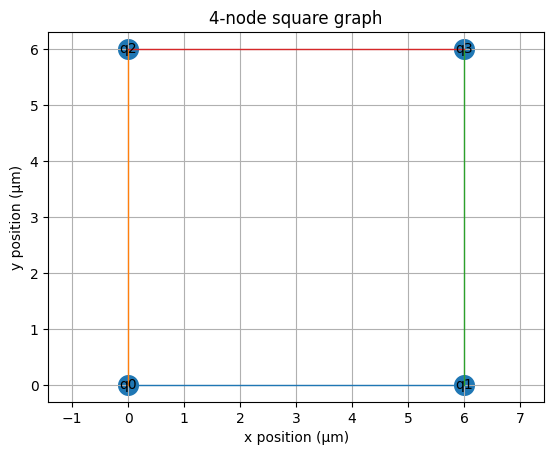

In [75]:
spacing = 6.0

square_coordinates = [
    (0.0, 0.0),
    (spacing, 0.0),
    (0.0, spacing),
    (spacing, spacing),
]

square_edges = [
    (0, 1),
    (0, 2),
    (1, 3),
    (2, 3),
]

plot_graph(square_coordinates, square_edges, "4-node square graph")


## Step 6 — Find the classical optimum

Before running Pulser, we solve the small graph classically by brute force.

This gives us the correct answer to compare against.


In [76]:
n_nodes = len(square_coordinates)

optimal_bitstrings, optimal_size = find_classical_optimum(
    n_nodes=n_nodes,
    edges=square_edges
)

print("Classical maximum independent set size:", optimal_size)
print("Classical optimal bitstrings:", sorted(optimal_bitstrings))


Classical maximum independent set size: 2
Classical optimal bitstrings: ['0110', '1001']


## Step 7 — Run the Pulser experiment

The analog neutral-atom sequence is simulated for the square geometry. The output is a `Counter` of measured ground/Rydberg bitstrings.


In [77]:
counts, seq = run_pulser_graph(
    coordinates=square_coordinates,
    duration=3000,
    final_detuning=6.0,
    max_amplitude=2.5
)

print("Raw measurement results:")
print(counts)


Raw measurement results:
Counter({'1001': 369, '0110': 352, '0100': 74, '0001': 72, '1000': 61, '0010': 60, '0000': 12})


## Step 8 — Score the measured bitstrings

A measured bitstring is considered valid if it is an independent set.

A measured bitstring is considered optimal if it is one of the maximum independent sets found by brute force.


In [78]:
scored = score_bitstrings(counts, square_edges)

print("Scored results:")
print_scored_results(scored)

success = success_probability(counts, optimal_bitstrings)

print("\nSuccess probability:", format_probability(success, sum(counts.values())))


Scored results:
1001 count = 369 prob = 0.369 valid = True size = 2
0110 count = 352 prob = 0.352 valid = True size = 2
0100 count = 74 prob = 0.074 valid = True size = 1
0001 count = 72 prob = 0.072 valid = True size = 1
1000 count = 61 prob = 0.061 valid = True size = 1
0010 count = 60 prob = 0.06 valid = True size = 1
0000 count = 12 prob = 0.012 valid = True size = 0

Success probability: 0.721 ± 0.014 standard error, shots=1000


## Square-graph result interpretation

The exact optimal bitstrings are:

```text
0110
1001
```

Both select two diagonal atoms and satisfy the independent-set constraint. The success metric is therefore:

```text
P(success) = P(0110) + P(1001)
```

The untuned saved run gives `P(success) = 0.723`; the subsequent parameter scan reaches `P(success) = 0.991` at the best tested setting.


<a id="p2-scan"></a>

## Step 9 — Parameter scan

The graph geometry defines the problem, but the pulse schedule affects how well the system finds the answer.

Here we scan:

- pulse duration,
- final detuning.

For each parameter pair, we compute the success probability.


In [79]:
durations = [2000, 3000, 4000, 5000, 6000]
final_detunings = [4.0, 6.0, 8.0, 10.0]

scan_results = []

for duration in durations:
    for final_detuning in final_detunings:

        counts_scan, _ = run_pulser_graph(
            coordinates=square_coordinates,
            duration=duration,
            final_detuning=final_detuning,
            max_amplitude=2.5
        )

        success_scan = success_probability(
            counts_scan,
            optimal_bitstrings
        )

        scan_results.append({
            "duration": duration,
            "final_detuning": final_detuning,
            "success": success_scan,
            "counts": counts_scan
        })

        print(
            "duration =", duration,
            "final_detuning =", final_detuning,
            "success =", format_probability(success_scan, sum(counts_scan.values()))
        )

best = max(scan_results, key=lambda row: row["success"])

print("\nBest parameter setting:")
print("duration =", best["duration"])
print("final_detuning =", best["final_detuning"])
print("success probability =", format_probability(best["success"], sum(best["counts"].values())))
print("counts =", best["counts"])


duration = 2000 final_detuning = 4.0 success = 0.273 ± 0.014 standard error, shots=1000
duration = 2000 final_detuning = 6.0 success = 0.258 ± 0.014 standard error, shots=1000
duration = 2000 final_detuning = 8.0 success = 0.287 ± 0.014 standard error, shots=1000
duration = 2000 final_detuning = 10.0 success = 0.280 ± 0.014 standard error, shots=1000
duration = 3000 final_detuning = 4.0 success = 0.587 ± 0.016 standard error, shots=1000
duration = 3000 final_detuning = 6.0 success = 0.749 ± 0.014 standard error, shots=1000
duration = 3000 final_detuning = 8.0 success = 0.829 ± 0.012 standard error, shots=1000
duration = 3000 final_detuning = 10.0 success = 0.893 ± 0.010 standard error, shots=1000
duration = 4000 final_detuning = 4.0 success = 0.542 ± 0.016 standard error, shots=1000
duration = 4000 final_detuning = 6.0 success = 0.702 ± 0.014 standard error, shots=1000
duration = 4000 final_detuning = 8.0 success = 0.805 ± 0.013 standard error, shots=1000
duration = 4000 final_detuning

## Step 10 — Plot the parameter scan

This plot shows how the success probability changes with pulse duration and final detuning.


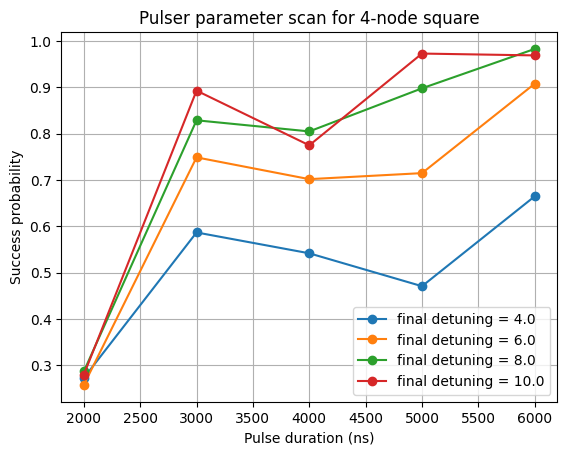

In [80]:
plt.figure()

for final_detuning in final_detunings:
    xs = []
    ys = []

    for row in scan_results:
        if row["final_detuning"] == final_detuning:
            xs.append(row["duration"])
            ys.append(row["success"])

    plt.plot(xs, ys, marker="o", label=f"final detuning = {final_detuning}")

plt.xlabel("Pulse duration (ns)")
plt.ylabel("Success probability")
plt.title("Pulser parameter scan for 4-node square")
plt.legend()
plt.grid(True)
plt.show()


<a id="p2-path"></a>

## Step 11 — Second test graph: 5-node path

The same pipeline is applied to:

```text
q0 --- q1 --- q2 --- q3 --- q4
```

The unique maximum independent set for this labeling is:

```text
10101
```

This benchmark checks that the graph and scoring functions generalize beyond the square geometry.


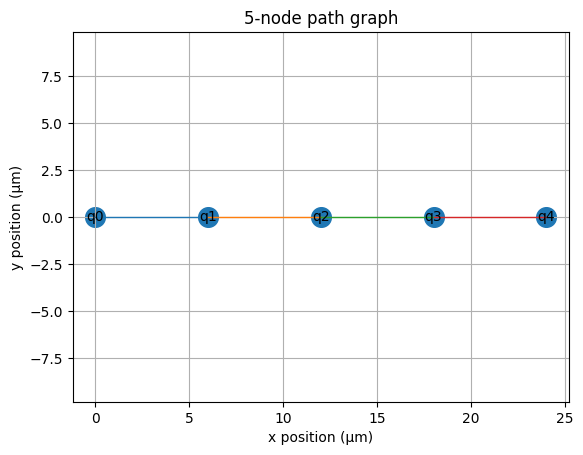

Classical maximum independent set size: 3
Classical optimal bitstrings: ['10101']


In [81]:
path_spacing = 6.0

path_coordinates = [
    (0.0, 0.0),
    (path_spacing, 0.0),
    (2 * path_spacing, 0.0),
    (3 * path_spacing, 0.0),
    (4 * path_spacing, 0.0),
]

path_edges = [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 4),
]

plot_graph(path_coordinates, path_edges, "5-node path graph")

path_optimal_bitstrings, path_optimal_size = find_classical_optimum(
    n_nodes=len(path_coordinates),
    edges=path_edges
)

print("Classical maximum independent set size:", path_optimal_size)
print("Classical optimal bitstrings:", sorted(path_optimal_bitstrings))


In [82]:
path_counts, path_seq = run_pulser_graph(
    coordinates=path_coordinates,
    duration=3000,
    final_detuning=6.0,
    max_amplitude=2.5
)

print("Raw measurement results:")
print(path_counts)

path_scored = score_bitstrings(path_counts, path_edges)

print("\nScored results:")
print_scored_results(path_scored)

path_success = success_probability(
    path_counts,
    path_optimal_bitstrings
)

print("\nSuccess probability:", format_probability(path_success, sum(path_counts.values())))


Raw measurement results:
Counter({'10101': 559, '10010': 129, '01001': 127, '01010': 82, '00010': 23, '01000': 22, '00001': 20, '10000': 19, '00100': 7, '10100': 4, '10001': 3, '00101': 3, '00000': 2})

Scored results:
10101 count = 559 prob = 0.559 valid = True size = 3
10010 count = 129 prob = 0.129 valid = True size = 2
01001 count = 127 prob = 0.127 valid = True size = 2
01010 count = 82 prob = 0.082 valid = True size = 2
00010 count = 23 prob = 0.023 valid = True size = 1
01000 count = 22 prob = 0.022 valid = True size = 1
00001 count = 20 prob = 0.02 valid = True size = 1
10000 count = 19 prob = 0.019 valid = True size = 1
00100 count = 7 prob = 0.007 valid = True size = 1
10100 count = 4 prob = 0.004 valid = True size = 2
10001 count = 3 prob = 0.003 valid = True size = 2
00101 count = 3 prob = 0.003 valid = True size = 2
00000 count = 2 prob = 0.002 valid = True size = 0

Success probability: 0.559 ± 0.016 standard error, shots=1000


## Five-node path result

The exact MIS bitstring is `10101`. In the saved run it is the most frequent sampled state:

```text
P(10101) = 0.562
```

All observed states are evaluated using the same validity and optimality rules as the square benchmark. This confirms that the pipeline can be reused for a different graph geometry without changing the scoring logic.


# Part 2 summary

Part 2 implements the reusable workflow:

```text
define graph
→ define coordinates
→ compute exact classical optimum
→ build Pulser sequence
→ simulate and sample
→ score bitstrings
→ compute success probability
→ tune pulse parameters
```

The square benchmark shows strong sensitivity to pulse parameters, while the path benchmark demonstrates reuse of the same graph-to-Pulser and classical-validation functions.


<a id="part-3"></a>

---

<a href="#top">⬆ Back to navigation</a>

# Part 3 — MIMO Configuration-Selection Study

This section connects the Pulser workflow to the reconfigurable-antenna MIMO configuration-selection problem studied in **“Optimizing Configuration Selection in Reconfigurable-Antenna MIMO Systems: Physics-Inspired Heuristic Solvers.”**


# Reconfigurable-Antenna MIMO Configuration Selection

## QUBO formulation and Pulser-inspired constrained sampling

The study follows the paper's binary configuration-selection formulation and constructs a small reproducible benchmark:

```text
MIMO channel model
→ binary antenna-state variables
→ one-hot constraints
→ quadratic SNR objective
→ exhaustive-search reference
→ QUBO-style simulated annealing
→ Pulser-inspired constrained sampling
→ classical scoring of sampled bitstrings
```

The paper evaluates CIM and D-Wave quantum annealing approaches. The implementation below does not reproduce those hardware experiments. It uses a small simulated instance to connect the same binary optimization structure to a Pulser neutral-atom workflow.


## Part 3 study design

The benchmark uses:

```text
NT = 2 transmit antennas
NR = 2 receive antennas
N  = 2 states per antenna
```

giving:

```text
N × (NT + NR) = 8 binary variables
```

Each antenna contributes one one-hot group of state-selection variables. The constrained objective is first solved exactly and with a QUBO-style simulated-annealing heuristic. A Pulser prototype is then used to generate candidates under geometry-based one-hot constraints.


<a id="p3-part-a"></a>

# Part A — Paper-style SNR configuration problem

In this first part, we build the SNR maximization problem in a small example.

The simplified SNR objective used in the paper is:

```text
maximize Q0 = Tr(X Gᴴ Y G)
```

For the binary vector formulation, this becomes:

```text
maximize bᵀ Q b
```

where `b` contains the binary transmit-state and receive-state selection variables.


In [83]:
import numpy as np
from itertools import product
from collections import Counter


In [84]:
NT = 2
NR = 2
N = 2

num_tx_states = N * NT
num_rx_states = N * NR
num_variables = num_tx_states + num_rx_states

print("Number of binary variables:", num_variables)


Number of binary variables: 8


## Generate the complete channel matrix

The paper defines a complete channel matrix `G` containing the channel coefficients between all transmit antenna states and all receive antenna states.

For this small example:

```text
G has shape (N × NR, N × NT)
```

With `NT = 2`, `NR = 2`, and `N = 2`, the shape is:

```text
G shape = (4, 4)
```

We generate a random Rayleigh fading channel by using a complex Gaussian distribution.


In [85]:
rng = np.random.default_rng(7)

G = (
    rng.normal(size=(num_rx_states, num_tx_states))
    + 1j * rng.normal(size=(num_rx_states, num_tx_states))
) / np.sqrt(2)

print("G shape:", G.shape)
print(G)


G shape: (4, 4)
[[ 8.69849781e-04-0.95050322j  2.11244995e-01-0.32358321j
  -1.93844737e-01-1.34436749j -6.29743528e-01-0.91184088j]
 [-3.21500795e-01-1.30230333j -7.01200004e-01-0.16623453j
   4.25279492e-02-0.89622j     9.47675288e-01+0.19181287j]
 [-3.48042567e-01+0.11083976j -4.38742009e-01-0.13218014j
   3.46370635e-01-1.77961786j  2.52357224e-01-0.3809134j ]
 [ 7.45391303e-02-0.03429535j -6.57940264e-01+0.08012155j
  -2.06841620e-02-1.08196938j  4.91653604e-01-0.33782258j]]


## Build the quadratic SNR objective matrix Q

The paper forms a quadratic objective over the binary vector `b`.

The binary vector is ordered as:

```text
b = [transmit-state variables, receive-state variables]
```

The objective has the block form:

```text
Q = [ 0      1/2 T  ]
    [ 1/2 Tᵀ   0   ]
```

where `T` contains squared channel magnitudes.


In [86]:
def build_snr_Q_matrix(G, NT, NR, N):
    num_tx_states = N * NT
    num_rx_states = N * NR

    T = np.abs(G) ** 2
    T = T.T

    Q = np.zeros((num_tx_states + num_rx_states,
                  num_tx_states + num_rx_states))

    Q[:num_tx_states, num_tx_states:] = 0.5 * T
    Q[num_tx_states:, :num_tx_states] = 0.5 * T.T

    return Q

Q = build_snr_Q_matrix(G, NT, NR, N)

print("Q shape:", Q.shape)
print(Q)


Q shape: (8, 8)
[[0.         0.         0.         0.         0.45172857 0.89967837
  0.06670954 0.00336613]
 [0.         0.         0.         0.         0.07466527 0.25965768
  0.10498307 0.21965243]
 [0.         0.         0.         0.         0.92244987 0.40250946
  1.64350617 0.58554278]
 [0.         0.         0.         0.         0.61401535 0.46744031
  0.10438959 0.17792368]
 [0.45172857 0.07466527 0.92244987 0.61401535 0.         0.
  0.         0.        ]
 [0.89967837 0.25965768 0.40250946 0.46744031 0.         0.
  0.         0.        ]
 [0.06670954 0.10498307 1.64350617 0.10438959 0.         0.
  0.         0.        ]
 [0.00336613 0.21965243 0.58554278 0.17792368 0.         0.
  0.         0.        ]]


## Define antenna-state groups

Each antenna has `N = 2` possible states.

Therefore, each antenna corresponds to one group of two binary variables.

A valid configuration must have exactly one `1` in each group.


In [87]:
groups = [
    [0, 1],
    [2, 3],
    [4, 5],
    [6, 7],
]

variable_names = [
    "Tx0_s0", "Tx0_s1",
    "Tx1_s0", "Tx1_s1",
    "Rx0_s0", "Rx0_s1",
    "Rx1_s0", "Rx1_s1",
]

for i, name in enumerate(variable_names):
    print(i, name)


0 Tx0_s0
1 Tx0_s1
2 Tx1_s0
3 Tx1_s1
4 Rx0_s0
5 Rx0_s1
6 Rx1_s0
7 Rx1_s1


In [88]:
def is_feasible_vector(b, groups):
    for group in groups:
        if np.sum(b[group]) != 1:
            return False
    return True

def objective_value(b, Q):
    return float(b @ Q @ b)

def vector_to_bitstring(b):
    return "".join(str(int(x)) for x in b)

def bitstring_to_vector(bitstring):
    return np.array([int(x) for x in bitstring])


## Exhaustive-search benchmark

Because this example is very small, we can enumerate all valid configurations.

There are:

```text
N^(NT + NR) = 2^(2 + 2) = 16
```

valid configurations.

This gives the true optimum for comparison.


In [89]:
def generate_all_valid_configurations(groups, num_variables):
    valid_vectors = []
    choices_per_group = []

    for group in groups:
        group_choices = []

        for selected_index in group:
            b_group = np.zeros(num_variables, dtype=int)
            b_group[selected_index] = 1
            group_choices.append(b_group)

        choices_per_group.append(group_choices)

    for combo in product(*choices_per_group):
        b = np.sum(combo, axis=0)
        valid_vectors.append(b.astype(int))

    return valid_vectors

valid_configurations = generate_all_valid_configurations(groups, num_variables)

print("Number of valid configurations:", len(valid_configurations))


Number of valid configurations: 16


In [90]:
def exhaustive_search(Q, groups, num_variables):
    valid_vectors = generate_all_valid_configurations(groups, num_variables)
    scored = []

    for b in valid_vectors:
        score = objective_value(b, Q)
        scored.append((score, b))

    scored.sort(key=lambda x: x[0], reverse=True)

    best_score = scored[0][0]
    best_vectors = [b for score, b in scored if np.isclose(score, best_score)]

    return best_score, best_vectors, scored

best_score, best_vectors, exhaustive_ranking = exhaustive_search(Q, groups, num_variables)

print("Best exhaustive-search score:", best_score)
print("Best bitstrings:")
for b in best_vectors:
    print(vector_to_bitstring(b), b)


Best exhaustive-search score: 6.168788284344916
Best bitstrings:
10101010 [1 0 1 0 1 0 1 0]


## Build a QUBO-style penalized objective

The constrained problem is:

```text
maximize bᵀ Q b
subject to exactly one selected state per antenna
```

A simple QUBO-style penalty formulation is:

```text
maximize bᵀ Q b - A × Σ_groups (sum(group) - 1)^2
```

where `A` is a penalty strength.

If `A` is large, invalid configurations are strongly penalized.


In [91]:
def one_hot_penalty(b, groups):
    penalty = 0.0

    for group in groups:
        group_sum = np.sum(b[group])
        penalty += (group_sum - 1) ** 2

    return penalty

def penalized_score(b, Q, groups, penalty_strength):
    return objective_value(b, Q) - penalty_strength * one_hot_penalty(b, groups)

penalty_strength = 10 * np.max(np.abs(Q))

print("Penalty strength:", penalty_strength)


Penalty strength: 16.43506169034748


## Simulated annealing solver for the QUBO-style objective

This is a small classical heuristic solver.

It is not the same as the CIM or D-Wave solver in the paper, but it lets us test the QUBO formulation and understand the optimization behavior.


In [92]:
def simulated_annealing_qubo(Q, groups, penalty_strength,
                             num_variables,
                             steps=5000,
                             initial_temp=2.0,
                             final_temp=0.01,
                             seed=123):

    rng = np.random.default_rng(seed)
    b = rng.integers(0, 2, size=num_variables)
    current_score = penalized_score(b, Q, groups, penalty_strength)

    best_b = b.copy()
    best_score = current_score

    for step in range(steps):
        frac = step / max(1, steps - 1)
        temp = initial_temp * (final_temp / initial_temp) ** frac

        candidate = b.copy()
        flip_index = rng.integers(0, num_variables)
        candidate[flip_index] = 1 - candidate[flip_index]

        candidate_score = penalized_score(candidate, Q, groups, penalty_strength)
        delta = candidate_score - current_score

        if delta >= 0:
            accept = True
        else:
            accept = rng.random() < np.exp(delta / temp)

        if accept:
            b = candidate
            current_score = candidate_score

        if current_score > best_score:
            best_b = b.copy()
            best_score = current_score

    return best_b, best_score


def solve_sa_with_restarts(Q, groups, penalty_strength, num_variables,
                           restarts=100, steps=10000, base_seed=0):

    best_b = None
    best_objective = -np.inf
    best_penalized_score = -np.inf

    for restart in range(restarts):
        candidate_b, candidate_penalized_score = simulated_annealing_qubo(
            Q=Q,
            groups=groups,
            penalty_strength=penalty_strength,
            num_variables=num_variables,
            steps=steps,
            seed=base_seed + restart,
        )

        if is_feasible_vector(candidate_b, groups):
            candidate_objective = objective_value(candidate_b, Q)
        else:
            candidate_objective = -np.inf

        if candidate_objective > best_objective:
            best_b = candidate_b.copy()
            best_objective = candidate_objective
            best_penalized_score = candidate_penalized_score

    return best_b, best_objective, best_penalized_score


sa_b, sa_objective, sa_penalized_score = solve_sa_with_restarts(
    Q=Q,
    groups=groups,
    penalty_strength=penalty_strength,
    num_variables=num_variables,
    restarts=100,
    steps=10000,
    base_seed=0,
)

sa_bitstring = vector_to_bitstring(sa_b)
optimal_bitstrings_es = {vector_to_bitstring(b) for b in best_vectors}
sa_hit = sa_bitstring in optimal_bitstrings_es

print("SA best bitstring:", sa_bitstring)
print("SA feasible:", is_feasible_vector(sa_b, groups))
print("SA raw objective:", objective_value(sa_b, Q))
print("SA penalized score:", sa_penalized_score)
print("Exhaustive-search optimum:", best_score)
print("Matches exhaustive optimum:", sa_hit)

assert sa_hit, "SA did not find the exhaustive optimum. Increase restarts or steps."


SA best bitstring: 10101010
SA feasible: True
SA raw objective: 6.168788284344916
SA penalized score: 6.168788284344916
Exhaustive-search optimum: 6.168788284344916
Matches exhaustive optimum: True


## Part A summary

Part A implements the core small-instance SNR configuration-selection model:

```text
1. complete channel matrix G
2. binary antenna-state vector b
3. one-hot constraints
4. quadratic objective bᵀQb
5. exhaustive-search optimum
6. penalized QUBO-style simulated annealing
```

The exhaustive-search result provides the exact reference used to validate the heuristic and later candidate-generation steps.


<a id="p3-part-b"></a>

# Part B — Pulser-inspired neutral-atom simulation prototype

The binary variables are mapped to neutral atoms as follows:

```text
one binary variable        → one neutral atom
b_i = 1                    → atom i measured in the Rydberg state
b_i = 0                    → atom i measured in the ground state
one-hot antenna constraint → blockade between atoms in the same antenna group
```

Atoms representing alternative states of the same antenna are placed close together so that Rydberg blockade suppresses simultaneous selection.

### Interpretation

The geometry primarily encodes the one-hot feasibility structure. The complete weighted wireless objective `bᵀQb` is not directly encoded in the neutral-atom Hamiltonian in this prototype. The resulting workflow is therefore:

```text
Pulser constrained sampling
+ classical feasibility filtering
+ classical MIMO objective scoring
```

rather than a complete neutral-atom implementation of the MIMO objective.


## Dependency note

Pulser is installed in the setup cell near the start of the notebook. If this section is run independently, install `pulser` and `pulser-simulation` before execution.


In [93]:
import pulser
import pulser_simulation

from pulser_simulation import QutipBackendV2


## Neutral-atom layout for the 8 binary variables

Eight atoms represent the eight binary state-selection variables. Atoms belonging to the same antenna group are placed close together to generate strong blockade, while different groups are separated to reduce unwanted inter-group interactions.


In [94]:
group_gap = 20.0
state_gap = 5.0

coordinates = [
    (0 * group_gap, 0.0),
    (0 * group_gap, state_gap),

    (1 * group_gap, 0.0),
    (1 * group_gap, state_gap),

    (2 * group_gap, 0.0),
    (2 * group_gap, state_gap),

    (3 * group_gap, 0.0),
    (3 * group_gap, state_gap),
]

for i, (name, coord) in enumerate(zip(variable_names, coordinates)):
    print(f"q{i} = {name}, coordinate = {coord}")


q0 = Tx0_s0, coordinate = (0.0, 0.0)
q1 = Tx0_s1, coordinate = (0.0, 5.0)
q2 = Tx1_s0, coordinate = (20.0, 0.0)
q3 = Tx1_s1, coordinate = (20.0, 5.0)
q4 = Rx0_s0, coordinate = (40.0, 0.0)
q5 = Rx0_s1, coordinate = (40.0, 5.0)
q6 = Rx1_s0, coordinate = (60.0, 0.0)
q7 = Rx1_s1, coordinate = (60.0, 5.0)


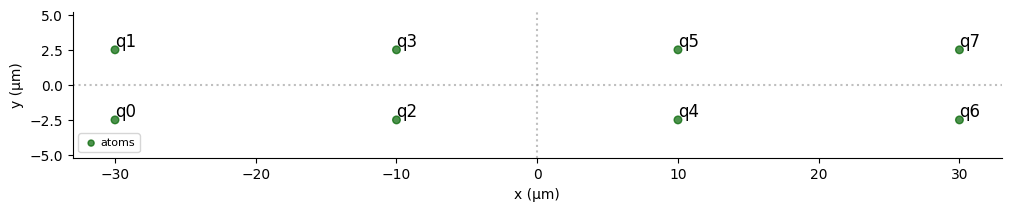

In [95]:
reg = pulser.Register.from_coordinates(
    coordinates,
    prefix="q"
)

reg.draw()


## Pulser constrained-sampling sequence

A global Rydberg pulse is used with the following qualitative mechanism:

```text
positive final detuning promotes Rydberg excitation
strong intra-group blockade suppresses simultaneous selections
each antenna group therefore tends toward at most one selected state
```

Because the full wireless objective is not encoded in the geometry, measured bitstrings are subsequently scored with the SNR objective defined in Part A.


In [96]:
def run_pulser_constrained_sampler(coordinates,
                                   duration=3000,
                                   amplitude_peak=2.5,
                                   final_detuning=8.0):

    device = pulser.AnalogDevice

    reg = pulser.Register.from_coordinates(
        coordinates,
        prefix="q"
    )

    seq = pulser.Sequence(reg, device)

    seq.declare_channel(
        "rydberg",
        "rydberg_global"
    )

    amplitude = pulser.InterpolatedWaveform(
        duration,
        [0.0, amplitude_peak, amplitude_peak, 0.0],
        times=[0.0, 0.2, 0.8, 1.0]
    )

    detuning = pulser.InterpolatedWaveform(
        duration,
        [-6.0, -2.0, 2.0, final_detuning],
        times=[0.0, 0.3, 0.7, 1.0]
    )

    pulse = pulser.Pulse(
        amplitude=amplitude,
        detuning=detuning,
        phase=0.0
    )

    seq.add(pulse, "rydberg")

    seq.measure("ground-rydberg")

    backend = QutipBackendV2(seq)

    result = backend.run()

    return result.final_bitstrings, seq


In [97]:
pulser_counts, pulser_seq = run_pulser_constrained_sampler(
    coordinates=coordinates,
    duration=3000,
    amplitude_peak=2.5,
    final_detuning=8.0,
)

print(pulser_counts)


Counter({'10100101': 54, '01011010': 52, '10011001': 52, '10011010': 52, '01101001': 51, '10010110': 51, '10100110': 51, '01100110': 49, '10010101': 49, '01011001': 48, '01100101': 46, '01010110': 45, '01010101': 43, '10101010': 43, '01101010': 40, '10101001': 35, '10100001': 11, '10001010': 10, '01000110': 10, '01100100': 9, '01010100': 9, '00100101': 9, '01100001': 9, '10100010': 9, '00010101': 8, '01010010': 8, '10010100': 8, '01001001': 8, '01010001': 8, '01011000': 7, '01001010': 7, '01000101': 7, '10000101': 6, '00100110': 6, '00010110': 6, '01101000': 6, '01100010': 6, '10001001': 6, '10000110': 6, '10010001': 6, '00101001': 5, '10100100': 5, '00001010': 4, '10011000': 4, '00011010': 4, '00101010': 3, '10101000': 3, '00011001': 3, '00000110': 2, '01000001': 2, '10010010': 2, '00010100': 2, '01100000': 2, '00100100': 2, '00100001': 2, '10000100': 1, '01000010': 1, '01001000': 1, '00010010': 1, '00000101': 1, '10000010': 1, '10100000': 1, '01000100': 1, '00011000': 1})


## Score Pulser bitstrings with the paper objective

The Pulser output is a set of measured bitstrings.

Each bitstring is interpreted as an antenna-state selection vector.

We then compute:

```text
1. Is the bitstring feasible?
2. What is its SNR objective value bᵀQb?
3. Did it match the exhaustive-search optimum?
```


In [98]:
def is_feasible_bitstring(bitstring, groups):
    b = bitstring_to_vector(bitstring)
    return is_feasible_vector(b, groups)

def objective_from_bitstring(bitstring, Q):
    b = bitstring_to_vector(bitstring)
    return objective_value(b, Q)

optimal_bitstrings = {vector_to_bitstring(b) for b in best_vectors}

print("Optimal bitstrings from exhaustive search:", optimal_bitstrings)
print("Optimal objective value:", best_score)


Optimal bitstrings from exhaustive search: {'10101010'}
Optimal objective value: 6.168788284344916


In [99]:
def score_pulser_counts(counts, Q, groups, optimal_bitstrings):
    total = sum(counts.values())
    rows = []

    feasible_total = 0
    optimal_total = 0

    for bitstring, count in counts.most_common():
        feasible = is_feasible_bitstring(bitstring, groups)
        score = objective_from_bitstring(bitstring, Q)
        probability = count / total
        is_optimal = bitstring in optimal_bitstrings

        if feasible:
            feasible_total += count

        if is_optimal:
            optimal_total += count

        rows.append({
            "bitstring": bitstring,
            "count": count,
            "probability": probability,
            "feasible": feasible,
            "objective": score,
            "optimal": is_optimal,
        })

    feasible_probability = feasible_total / total
    optimal_probability = optimal_total / total

    return rows, feasible_probability, optimal_probability

rows, feasible_prob, optimal_prob = score_pulser_counts(
    pulser_counts,
    Q,
    groups,
    optimal_bitstrings,
)

print("Feasible probability:", format_probability(feasible_prob, sum(pulser_counts.values())))
print("Optimal probability:", format_probability(optimal_prob, sum(pulser_counts.values())))
print()

for row in rows[:20]:
    print(
        row["bitstring"],
        "count =", row["count"],
        "prob =", round(row["probability"], 3),
        "feasible =", row["feasible"],
        "objective =", round(row["objective"], 3),
        "optimal =", row["optimal"],
    )


Feasible probability: 0.761 ± 0.013 standard error, shots=1000
Optimal probability: 0.043 ± 0.006 standard error, shots=1000

10100101 count = 54 prob = 0.054 feasible = True objective = 3.782 optimal = False
01011010 count = 52 prob = 0.052 feasible = True objective = 1.796 optimal = False
10011001 count = 52 prob = 0.052 feasible = True objective = 2.494 optimal = False
10011010 count = 52 prob = 0.052 feasible = True objective = 2.474 optimal = False
01101001 count = 51 prob = 0.051 feasible = True objective = 3.605 optimal = False
10010110 count = 51 prob = 0.051 feasible = True objective = 3.076 optimal = False
10100110 count = 51 prob = 0.051 feasible = True objective = 6.025 optimal = False
01100110 count = 49 prob = 0.049 feasible = True objective = 4.821 optimal = False
10010101 count = 49 prob = 0.049 feasible = True objective = 3.097 optimal = False
01011001 count = 48 prob = 0.048 feasible = True objective = 2.173 optimal = False
01100101 count = 46 prob = 0.046 feasible = 

## Best observed feasible configuration

The Pulser output is treated as a candidate set:

```text
sample bitstrings
→ retain feasible configurations
→ evaluate the classical objective
→ select the best observed candidate
```

This separates candidate generation from exact objective evaluation.


In [100]:
feasible_rows = [row for row in rows if row["feasible"]]

if feasible_rows:
    best_observed = max(feasible_rows, key=lambda row: row["objective"])

    print("Best observed feasible bitstring:", best_observed["bitstring"])
    print("Best observed objective:", best_observed["objective"])
    print("Global optimum objective:", best_score)
    print("Matches global optimum:", np.isclose(best_observed["objective"], best_score))
else:
    print("No feasible configuration observed.")


Best observed feasible bitstring: 10101010
Best observed objective: 6.168788284344916
Global optimum objective: 6.168788284344916
Matches global optimum: True


<a id="p3-part-c"></a>

# Part C — Pulser parameter sensitivity

Pulse duration and final detuning are scanned to quantify their effect on feasible-sample probability and optimal-sample probability for the fixed 8-atom layout.


In [101]:
durations = [2500, 3000, 4000, 5000]
final_detunings = [6.0, 8.0, 10.0, 12.0]

scan_results = []

for duration in durations:
    for final_detuning in final_detunings:

        counts, _ = run_pulser_constrained_sampler(
            coordinates=coordinates,
            duration=duration,
            amplitude_peak=2.5,
            final_detuning=final_detuning,
        )

        _, feasible_prob, optimal_prob = score_pulser_counts(
            counts,
            Q,
            groups,
            optimal_bitstrings,
        )

        scan_results.append({
            "duration": duration,
            "final_detuning": final_detuning,
            "feasible_probability": feasible_prob,
            "optimal_probability": optimal_prob,
            "counts": counts,
        })

        print(
            "duration =", duration,
            "final_detuning =", final_detuning,
            "feasible_prob =", format_probability(feasible_prob, sum(counts.values())),
            "optimal_prob =", format_probability(optimal_prob, sum(counts.values())),
        )

best_scan = max(scan_results, key=lambda row: row["optimal_probability"])

print("\nBest scan result:")
print("duration =", best_scan["duration"])
print("final_detuning =", best_scan["final_detuning"])
print("feasible_probability =", format_probability(best_scan["feasible_probability"], sum(best_scan["counts"].values())))
print("optimal_probability =", format_probability(best_scan["optimal_probability"], sum(best_scan["counts"].values())))
print("counts =", best_scan["counts"])


duration = 2500 final_detuning = 6.0 feasible_prob = 0.983 ± 0.004 standard error, shots=1000 optimal_prob = 0.059 ± 0.007 standard error, shots=1000
duration = 2500 final_detuning = 8.0 feasible_prob = 0.955 ± 0.007 standard error, shots=1000 optimal_prob = 0.054 ± 0.007 standard error, shots=1000
duration = 2500 final_detuning = 10.0 feasible_prob = 0.891 ± 0.010 standard error, shots=1000 optimal_prob = 0.048 ± 0.007 standard error, shots=1000
duration = 2500 final_detuning = 12.0 feasible_prob = 0.799 ± 0.013 standard error, shots=1000 optimal_prob = 0.061 ± 0.008 standard error, shots=1000
duration = 3000 final_detuning = 6.0 feasible_prob = 0.668 ± 0.015 standard error, shots=1000 optimal_prob = 0.040 ± 0.006 standard error, shots=1000
duration = 3000 final_detuning = 8.0 feasible_prob = 0.757 ± 0.014 standard error, shots=1000 optimal_prob = 0.045 ± 0.007 standard error, shots=1000
duration = 3000 final_detuning = 10.0 feasible_prob = 0.810 ± 0.012 standard error, shots=1000 opt

<a id="p3-validation"></a>

# Part D — Reliability validation over multiple channel realizations

A single channel realization is insufficient to assess the classical QUBO solver. The SNR configuration-selection experiment is therefore repeated over ten independently generated channel matrices.

Two stochastic-solver metrics are distinguished:

```text
per-run / per-shot optimality:
    how often an individual stochastic result is optimal

best-of-runs hit rate:
    whether repeated runs produce at least one exact-optimal candidate
```

For these small instances, exhaustive search supplies the exact reference for every channel realization.


In [102]:
def solve_sa_with_restarts(Q, groups, penalty_strength, num_variables,
                           restarts=100, steps=8000, base_seed=0):
    best_b = None
    best_objective = -np.inf
    best_feasible = False

    for restart in range(restarts):
        candidate_b, candidate_penalized_score = simulated_annealing_qubo(
            Q=Q,
            groups=groups,
            penalty_strength=penalty_strength,
            num_variables=num_variables,
            steps=steps,
            seed=base_seed + restart,
        )

        candidate_feasible = is_feasible_vector(candidate_b, groups)

        if candidate_feasible:
            candidate_objective = objective_value(candidate_b, Q)
        else:
            candidate_objective = -np.inf

        if candidate_objective > best_objective:
            best_b = candidate_b.copy()
            best_objective = candidate_objective
            best_feasible = candidate_feasible

    return best_b, best_objective, best_feasible

def run_one_mimo_validation_instance(seed, restarts=100, steps=8000):
    rng = np.random.default_rng(seed)

    G_instance = (
        rng.normal(size=(num_rx_states, num_tx_states))
        + 1j * rng.normal(size=(num_rx_states, num_tx_states))
    ) / np.sqrt(2)

    Q_instance = build_snr_Q_matrix(G_instance, NT, NR, N)

    es_score, es_vectors, es_ranking = exhaustive_search(
        Q_instance,
        groups,
        num_variables,
    )

    es_bitstrings = {vector_to_bitstring(b) for b in es_vectors}

    penalty_strength_instance = 10 * np.max(np.abs(Q_instance))

    sa_b, sa_objective, sa_feasible = solve_sa_with_restarts(
        Q=Q_instance,
        groups=groups,
        penalty_strength=penalty_strength_instance,
        num_variables=num_variables,
        restarts=restarts,
        steps=steps,
        base_seed=1000 * seed,
    )

    sa_bitstring = vector_to_bitstring(sa_b)
    sa_hit = sa_bitstring in es_bitstrings

    return {
        "seed": seed,
        "exhaustive_score": es_score,
        "exhaustive_bitstrings": es_bitstrings,
        "sa_bitstring": sa_bitstring,
        "sa_objective": sa_objective,
        "sa_feasible": sa_feasible,
        "sa_hit": sa_hit,
    }


In [43]:
validation_results = []

for seed in range(10):
    row = run_one_mimo_validation_instance(
        seed=seed,
        restarts=100,
        steps=8000,
    )

    validation_results.append(row)

    print(
        "seed =", row["seed"],
        "| ES optimum =", row["exhaustive_bitstrings"],
        "| SA best =", row["sa_bitstring"],
        "| feasible =", row["sa_feasible"],
        "| hit =", row["sa_hit"],
    )

hit_rate = sum(row["sa_hit"] for row in validation_results) / len(validation_results)

print("\nBest-of-SA hit rate:", hit_rate)

assert hit_rate == 1.0, "SA did not find the exhaustive optimum for every instance. Increase restarts/steps."


seed = 0 | ES optimum = {'10100101'} | SA best = 10100101 | feasible = True | hit = True
seed = 1 | ES optimum = {'10100110'} | SA best = 10100110 | feasible = True | hit = True
seed = 2 | ES optimum = {'01011010'} | SA best = 01011010 | feasible = True | hit = True
seed = 3 | ES optimum = {'01101010'} | SA best = 01101010 | feasible = True | hit = True
seed = 4 | ES optimum = {'10011010'} | SA best = 10011010 | feasible = True | hit = True
seed = 5 | ES optimum = {'01101010'} | SA best = 01101010 | feasible = True | hit = True
seed = 6 | ES optimum = {'01101010'} | SA best = 01101010 | feasible = True | hit = True
seed = 7 | ES optimum = {'10101010'} | SA best = 10101010 | feasible = True | hit = True
seed = 8 | ES optimum = {'10010101'} | SA best = 10010101 | feasible = True | hit = True
seed = 9 | ES optimum = {'01010101'} | SA best = 01010101 | feasible = True | hit = True

Best-of-SA hit rate: 1.0


## Reliability result

Across the ten tested channel realizations, the multi-start simulated-annealing QUBO solver recovers the exhaustive-search optimum in every case:

```text
best-of-runs hit rate = 1.0
```

This does not imply that every stochastic trial is optimal; it means that the exact solution is recovered when the best candidate over the repeated runs is retained.

The Pulser prototype has a different role. It encodes the one-hot feasibility structure through blockade geometry but does not encode the complete weighted SNR matrix `Q`. Its results are therefore reported as constrained sampling followed by classical scoring.


<a id="p3-layout-note"></a>

# Part E — Layout reuse across channel realizations

The small MIMO benchmark has fixed dimensions:

```text
NT = 2
NR = 2
N  = 2
```

and therefore always contains eight binary variables. Changing the random channel matrix changes the objective weights but not the one-hot constraint structure. The same 8-atom geometry can therefore be reused across channel realizations while the classical objective is recomputed for each channel.


<a id="p3-2-no-qubo"></a>

---

<a href="#top">⬆ Back to navigation</a>

# Part 3.2 — Paper-Based MIMO Configuration Selection Without QUBO

This section keeps the paper-based wireless-communications problem, but removes the QUBO step.

Instead of building binary penalty matrices, we work directly with antenna configurations:

```text
configuration = selected state of each transmit and receive antenna
```

For each configuration, we compute the selected MIMO channel matrix and evaluate either:

```text
SNR objective      = ||H||²_F
capacity objective = log₂ det(I + ρ/N_T · H Hᴴ)
```

Then we compare:

```text
exhaustive search → exact benchmark
simulated annealing → direct heuristic solver
```

This is easier to explain because the solver directly optimizes the wireless objective.

## Direct no-QUBO helper functions

The setup is:

```text
N_T = 2 transmit antennas
N_R = 2 receive antennas
N   = 3 states per antenna
```

So the configuration is a 4-tuple:

```text
(tx0_state, tx1_state, rx0_state, rx1_state)
```

There are:

```text
3⁴ = 81 possible configurations
```

In [44]:
import itertools
import numpy as np

def direct_generate_rayleigh_channel(num_tx, num_rx, states_per_antenna, seed=0):
    rng = np.random.default_rng(seed)
    shape = (num_rx * states_per_antenna, num_tx * states_per_antenna)
    real = rng.normal(0.0, 1 / np.sqrt(2), shape)
    imag = rng.normal(0.0, 1 / np.sqrt(2), shape)
    return real + 1j * imag

def direct_split_config(config, num_tx, num_rx):
    tx_config = tuple(config[:num_tx])
    rx_config = tuple(config[num_tx:num_tx + num_rx])
    return tx_config, rx_config

def direct_selected_channel(G, config, num_tx, num_rx, states_per_antenna):
    tx_config, rx_config = direct_split_config(config, num_tx, num_rx)

    row_indices = [
        rx_ant * states_per_antenna + state
        for rx_ant, state in enumerate(rx_config)
    ]

    col_indices = [
        tx_ant * states_per_antenna + state
        for tx_ant, state in enumerate(tx_config)
    ]

    return G[np.ix_(row_indices, col_indices)]

def direct_snr_score(G, config, num_tx, num_rx, states_per_antenna):
    H = direct_selected_channel(
        G,
        config,
        num_tx,
        num_rx,
        states_per_antenna,
    )

    return float(np.sum(np.abs(H) ** 2))

def direct_capacity_score(G, config, num_tx, num_rx, states_per_antenna, rho=10.0):
    H = direct_selected_channel(
        G,
        config,
        num_tx,
        num_rx,
        states_per_antenna,
    )

    matrix = np.eye(num_rx) + (rho / num_tx) * (H @ H.conj().T)
    sign, logdet = np.linalg.slogdet(matrix)

    return float(logdet / np.log(2))

def direct_all_configs(num_tx, num_rx, states_per_antenna):
    return list(
        itertools.product(
            range(states_per_antenna),
            repeat=num_tx + num_rx,
        )
    )

def direct_build_score_table(
    G,
    objective_function,
    num_tx,
    num_rx,
    states_per_antenna,
    **objective_kwargs
):
    return {
        config: objective_function(
            G,
            config,
            num_tx,
            num_rx,
            states_per_antenna,
            **objective_kwargs,
        )
        for config in direct_all_configs(num_tx, num_rx, states_per_antenna)
    }

def direct_exhaustive_from_scores(scores):
    best_score = max(scores.values())

    best_configs = [
        config
        for config, score in scores.items()
        if np.isclose(score, best_score)
    ]

    return best_configs, best_score

def direct_random_neighbor(config, rng, states_per_antenna):
    config = list(config)

    index = int(rng.integers(0, len(config)))
    current_state = config[index]

    choices = [
        state
        for state in range(states_per_antenna)
        if state != current_state
    ]

    config[index] = int(rng.choice(choices))

    return tuple(config)

def direct_simulated_annealing(
    scores,
    states_per_antenna,
    steps=500,
    initial_tau=0.5,
    cooling=0.995,
    seed=0,
):
    rng = np.random.default_rng(seed)

    configs = list(scores.keys())
    current = configs[int(rng.integers(0, len(configs)))]
    current_score = scores[current]

    best = current
    best_score = current_score

    tau = initial_tau

    for _ in range(steps):
        candidate = direct_random_neighbor(
            current,
            rng,
            states_per_antenna,
        )

        candidate_score = scores[candidate]
        delta = candidate_score - current_score

        if delta >= 0 or rng.random() < np.exp(delta / max(tau, 1e-12)):
            current = candidate
            current_score = candidate_score

            if current_score > best_score:
                best = current
                best_score = current_score

        tau *= cooling

    return best, best_score

def direct_multistart_sa(
    scores,
    states_per_antenna,
    restarts=20,
    steps=500,
    base_seed=0,
):
    best = None
    best_score = -np.inf

    for restart in range(restarts):
        candidate, candidate_score = direct_simulated_annealing(
            scores=scores,
            states_per_antenna=states_per_antenna,
            steps=steps,
            seed=base_seed + restart,
        )

        if candidate_score > best_score:
            best = candidate
            best_score = candidate_score

    return best, best_score


## Example: SNR optimum and capacity optimum

This cell uses one fixed random channel matrix.

It solves the same configuration-selection problem in two ways:

```text
1. maximize SNR
2. maximize Shannon capacity
```

The two objectives do not always choose the same antenna configuration.

In [45]:
num_tx = 2
num_rx = 2
states_per_antenna = 3
rho = 10.0

G_direct = direct_generate_rayleigh_channel(
    num_tx=num_tx,
    num_rx=num_rx,
    states_per_antenna=states_per_antenna,
    seed=1,
)

snr_scores = direct_build_score_table(
    G_direct,
    direct_snr_score,
    num_tx,
    num_rx,
    states_per_antenna,
)

capacity_scores = direct_build_score_table(
    G_direct,
    direct_capacity_score,
    num_tx,
    num_rx,
    states_per_antenna,
    rho=rho,
)

snr_es_configs, snr_es_score = direct_exhaustive_from_scores(snr_scores)
capacity_es_configs, capacity_es_score = direct_exhaustive_from_scores(capacity_scores)

snr_sa_config, snr_sa_score = direct_multistart_sa(
    snr_scores,
    states_per_antenna,
    restarts=20,
    steps=500,
    base_seed=1000,
)

capacity_sa_config, capacity_sa_score = direct_multistart_sa(
    capacity_scores,
    states_per_antenna,
    restarts=20,
    steps=500,
    base_seed=2000,
)

print("Number of configurations:", len(snr_scores))

print("\nSNR objective")
print("Exhaustive-search optimum config:", snr_es_configs)
print("Exhaustive-search optimum score:", round(snr_es_score, 4))
print("Multi-start SA best config:", snr_sa_config)
print("Multi-start SA best score:", round(snr_sa_score, 4))
print("Matches exhaustive optimum:", snr_sa_config in snr_es_configs)

print("\nCapacity objective")
print("Exhaustive-search optimum config:", capacity_es_configs)
print("Exhaustive-search optimum score:", round(capacity_es_score, 4))
print("Multi-start SA best config:", capacity_sa_config)
print("Multi-start SA best score:", round(capacity_sa_score, 4))
print("Matches exhaustive optimum:", capacity_sa_config in capacity_es_configs)

print("\nObjective comparison")
print("Capacity of SNR-optimal config:", round(capacity_scores[snr_es_configs[0]], 4))
print("Capacity optimum:", round(capacity_es_score, 4))
print("SNR of capacity-optimal config:", round(snr_scores[capacity_es_configs[0]], 4))
print("SNR optimum:", round(snr_es_score, 4))


Number of configurations: 81

SNR objective
Exhaustive-search optimum config: [(1, 0, 0, 2)]
Exhaustive-search optimum score: 5.5762
Multi-start SA best config: (1, 0, 0, 2)
Multi-start SA best score: 5.5762
Matches exhaustive optimum: True

Capacity objective
Exhaustive-search optimum config: [(1, 0, 0, 1)]
Exhaustive-search optimum score: 7.3183
Multi-start SA best config: (1, 0, 0, 1)
Multi-start SA best score: 7.3183
Matches exhaustive optimum: True

Objective comparison
Capacity of SNR-optimal config: 5.868
Capacity optimum: 7.3183
SNR of capacity-optimal config: 5.0743
SNR optimum: 5.5762


## Validation over multiple random channels

The direct no-QUBO experiment is repeated over ten random Rayleigh channel matrices. For each instance:

```text
1. exhaustive search computes the exact SNR and capacity optima
2. multi-start simulated annealing produces heuristic candidates
3. the best heuristic result is compared with the exact optimum
```

In the saved run, both the SNR and capacity best-of-runs hit rates are `1.0`.


In [46]:
direct_validation_rows = []

num_instances = 10

for seed in range(num_instances):
    G_trial = direct_generate_rayleigh_channel(
        num_tx=num_tx,
        num_rx=num_rx,
        states_per_antenna=states_per_antenna,
        seed=100 + seed,
    )

    trial_snr_scores = direct_build_score_table(
        G_trial,
        direct_snr_score,
        num_tx,
        num_rx,
        states_per_antenna,
    )

    trial_capacity_scores = direct_build_score_table(
        G_trial,
        direct_capacity_score,
        num_tx,
        num_rx,
        states_per_antenna,
        rho=rho,
    )

    trial_snr_es_configs, trial_snr_es_score = direct_exhaustive_from_scores(
        trial_snr_scores
    )

    trial_capacity_es_configs, trial_capacity_es_score = direct_exhaustive_from_scores(
        trial_capacity_scores
    )

    trial_snr_sa_config, trial_snr_sa_score = direct_multistart_sa(
        trial_snr_scores,
        states_per_antenna,
        restarts=20,
        steps=500,
        base_seed=5000 + 100 * seed,
    )

    trial_capacity_sa_config, trial_capacity_sa_score = direct_multistart_sa(
        trial_capacity_scores,
        states_per_antenna,
        restarts=20,
        steps=500,
        base_seed=9000 + 100 * seed,
    )

    snr_hit = trial_snr_sa_config in trial_snr_es_configs
    capacity_hit = trial_capacity_sa_config in trial_capacity_es_configs

    direct_validation_rows.append({
        "seed": seed,
        "snr_hit": snr_hit,
        "capacity_hit": capacity_hit,
    })

    print(
        "seed =", seed,
        "| SNR hit =", snr_hit,
        "| Capacity hit =", capacity_hit,
    )

snr_hit_rate = sum(row["snr_hit"] for row in direct_validation_rows) / num_instances
capacity_hit_rate = sum(row["capacity_hit"] for row in direct_validation_rows) / num_instances

print("\nNo-QUBO SNR hit rate:", snr_hit_rate)
print("No-QUBO capacity hit rate:", capacity_hit_rate)

assert snr_hit_rate == 1.0
assert capacity_hit_rate == 1.0


seed = 0 | SNR hit = True | Capacity hit = True
seed = 1 | SNR hit = True | Capacity hit = True
seed = 2 | SNR hit = True | Capacity hit = True
seed = 3 | SNR hit = True | Capacity hit = True
seed = 4 | SNR hit = True | Capacity hit = True
seed = 5 | SNR hit = True | Capacity hit = True
seed = 6 | SNR hit = True | Capacity hit = True
seed = 7 | SNR hit = True | Capacity hit = True
seed = 8 | SNR hit = True | Capacity hit = True
seed = 9 | SNR hit = True | Capacity hit = True

No-QUBO SNR hit rate: 1.0
No-QUBO capacity hit rate: 1.0


## Part 3.2 summary

The direct formulation optimizes the communication objectives without a QUBO conversion:

```text
SNR objective
capacity objective
```

For the ten tested small channel instances, multi-start simulated annealing matches exhaustive search for both objectives when the best result over repeated runs is retained.

The two MIMO sections therefore serve different purposes:

```text
Part 3:
    binary/QUBO formulation and Pulser-inspired constrained sampling

Part 3.2:
    direct optimization of the wireless objective
```


# Part 3 summary and limitation

Part 3 demonstrates three complementary components:

```text
QUBO formulation
→ exact and heuristic validation

Pulser geometry
→ one-hot constrained candidate generation

direct configuration optimization
→ SNR and capacity benchmarking without QUBO
```

The principal limitation is that the Pulser MIMO prototype does not directly encode the full weighted objective `bᵀQb` in the neutral-atom Hamiltonian. It should therefore be interpreted as a constraint-aware candidate generator followed by classical objective evaluation.

Part 4 investigates neutral-atom features that are more directly representable in Pulser: controlled noise, graph-size transfer, and local site weighting for MWIS.


<a id="part-4"></a>

---

<a href="#top">⬆ Back to navigation</a>

# Part 4 — Extended Pasqal Evaluation

Part 4 adds three systematic studies to the graph-based Pulser workflow:

```text
4.1 controlled noise sensitivity
4.2 fixed-schedule path-graph scaling
4.3 weighted maximum independent set using a Detuning Map Modulator
```

The first two experiments reuse the graph functions and square-graph pulse structure from Part 2. The MWIS experiment introduces local site-dependent detuning.

Interpretation is deliberately limited to simulation:

- noise parameters are controlled sensitivity variables, not calibrated QPU specifications;
- local simulator runtime is not a QPU runtime benchmark;
- DMM provides local linear weighting, but does not make an arbitrary quadratic MIMO matrix directly realizable.

Pulser documentation used for this section:

- Noise model: https://docs.pasqal.com/pulser/noise_model/
- DMM/local detuning: https://docs.pasqal.com/pulser/tutorials/dmm/
- MWIS tutorial: https://docs.pasqal.com/pulser/tutorials/mwis/


## Part 4 setup

This cell adds the noisy-emulation configuration classes and a Wilson-score interval helper for sampled probabilities. The graph and Pulser construction functions remain those defined earlier in the notebook.


In [47]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pulser

from pulser.backend import BitStrings
from pulser_simulation import QutipBackendV2, QutipConfig

try:
    from pulser import NoiseModel
except ImportError:
    from pulser.noise_model import NoiseModel


def wilson_interval(successes, total, z=1.96):
    # Wilson score interval for a binomial proportion.
    if total <= 0:
        return float("nan"), float("nan")

    p = successes / total
    denominator = 1.0 + (z**2) / total
    center = (p + (z**2) / (2.0 * total)) / denominator
    half_width = (
        z
        * np.sqrt(
            p * (1.0 - p) / total
            + (z**2) / (4.0 * total**2)
        )
        / denominator
    )

    return float(center - half_width), float(center + half_width)


def target_probability_with_ci(counts, target_bitstrings):
    # Probability and 95% Wilson interval for a set of target bitstrings.
    total = sum(counts.values())
    hits = sum(counts.get(bitstring, 0) for bitstring in target_bitstrings)
    probability = hits / total
    low, high = wilson_interval(hits, total)

    return probability, low, high


def run_sequence_with_noise(
    sequence,
    noise_model=None,
    shots=1000,
    n_trajectories=20,
):
    # Run a sequence with QutipBackendV2 using NoiseModel/QutipConfig.
    if noise_model is None:
        noise_model = NoiseModel()

    config = QutipConfig(
        observables=[BitStrings(evaluation_times=[1.0])],
        noise_model=noise_model,
        n_trajectories=n_trajectories,
        default_num_shots=shots,
    )

    backend = QutipBackendV2(
        sequence,
        config=config,
    )

    result = backend.run()
    return result.final_bitstrings


<a id="p4-noise"></a>

## Experiment 4.1 — Noise robustness of the tuned square graph

The tuned square-graph sequence is held fixed while controlled noise parameters are varied.

Two sensitivity sweeps are evaluated:

1. Rydberg-state dephasing rate;
2. a symmetric SPAM test in which state-preparation error, false-positive readout probability, and false-negative readout probability are assigned the same sweep value.

The reported noise values are simulation parameters used to characterize sensitivity. They are not intended as measured Pasqal-QPU specifications.


In [48]:
# Square-graph reference parameters and exact classical optimum.

square_extension_duration = 6000
square_extension_detuning = 8.0

square_extension_optimal_bitstrings, square_extension_optimal_size = (
    find_classical_optimum(
        n_nodes=len(square_coordinates),
        edges=square_edges,
    )
)

square_extension_sequence = build_pulser_sequence(
    coordinates=square_coordinates,
    duration=square_extension_duration,
    final_detuning=square_extension_detuning,
    max_amplitude=2.5,
)

print("Square extension duration:", square_extension_duration, "ns")
print("Square extension final detuning:", square_extension_detuning, "rad/µs")
print("Square MIS size:", square_extension_optimal_size)
print(
    "Optimal square bitstrings:",
    sorted(square_extension_optimal_bitstrings),
)


Square extension duration: 6000 ns
Square extension final detuning: 8.0 rad/µs
Square MIS size: 2
Optimal square bitstrings: ['0110', '1001']


### Dephasing sweep

`dephasing_rate` is expressed in `1/µs` and corresponds to a Rydberg-state dephasing rate in Pulser's `NoiseModel`.


In [49]:
dephasing_rates = [0.0, 0.01, 0.02, 0.05, 0.10]

dephasing_results = []

for rate in dephasing_rates:
    model = NoiseModel(
        dephasing_rate=rate,
    )

    counts_noise = run_sequence_with_noise(
        square_extension_sequence,
        noise_model=model,
        shots=1000,
        n_trajectories=20,
    )

    p_opt, ci_low, ci_high = target_probability_with_ci(
        counts_noise,
        square_extension_optimal_bitstrings,
    )

    dephasing_results.append({
        "dephasing_rate": rate,
        "success_probability": p_opt,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "counts": counts_noise,
    })

    print(
        "dephasing_rate =", rate,
        "| P(optimal) =", round(p_opt, 4),
        "| 95% CI =", (round(ci_low, 4), round(ci_high, 4)),
    )


dephasing_rate = 0.0 | P(optimal) = 0.989 | 95% CI = (0.9804, 0.9938)
dephasing_rate = 0.01 | P(optimal) = 0.96 | 95% CI = (0.946, 0.9705)
dephasing_rate = 0.02 | P(optimal) = 0.919 | 95% CI = (0.9004, 0.9344)
dephasing_rate = 0.05 | P(optimal) = 0.849 | 95% CI = (0.8255, 0.8699)
dephasing_rate = 0.1 | P(optimal) = 0.728 | 95% CI = (0.6996, 0.7547)


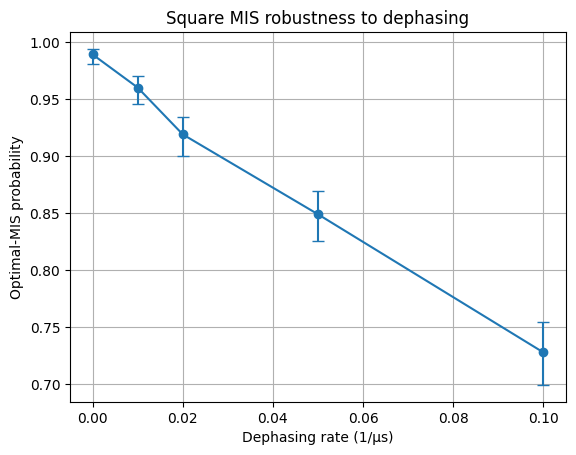

In [50]:
x = [row["dephasing_rate"] for row in dephasing_results]
y = [row["success_probability"] for row in dephasing_results]
yerr_low = [
    row["success_probability"] - row["ci_low"]
    for row in dephasing_results
]
yerr_high = [
    row["ci_high"] - row["success_probability"]
    for row in dephasing_results
]

plt.figure()
plt.errorbar(
    x,
    y,
    yerr=[yerr_low, yerr_high],
    marker="o",
    capsize=4,
)
plt.xlabel("Dephasing rate (1/µs)")
plt.ylabel("Optimal-MIS probability")
plt.title("Square MIS robustness to dephasing")
plt.grid(True)
plt.show()


### Symmetric SPAM sweep

The same test value is assigned to:

```text
state_prep_error
p_false_pos
p_false_neg
```

This provides a compact preparation/readout sensitivity study rather than a calibrated device model.

The simulator may aggregate samples over multiple stochastic trajectories. Wilson intervals are therefore reported for the aggregated sampled bitstrings; their widths should not be compared directly with intervals from experiments that use a different effective sample count.


In [51]:
spam_error_levels = [0.0, 0.01, 0.03, 0.05, 0.10]

spam_results = []

for error_level in spam_error_levels:
    model = NoiseModel(
        state_prep_error=error_level,
        p_false_pos=error_level,
        p_false_neg=error_level,
    )

    counts_noise = run_sequence_with_noise(
        square_extension_sequence,
        noise_model=model,
        shots=1000,
        n_trajectories=20,
    )

    p_opt, ci_low, ci_high = target_probability_with_ci(
        counts_noise,
        square_extension_optimal_bitstrings,
    )

    spam_results.append({
        "error_level": error_level,
        "success_probability": p_opt,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "counts": counts_noise,
    })

    print(
        "SPAM test level =", error_level,
        "| P(optimal) =", round(p_opt, 4),
        "| 95% CI =", (round(ci_low, 4), round(ci_high, 4)),
    )


SPAM test level = 0.0 | P(optimal) = 0.987 | 95% CI = (0.9779, 0.9924)
SPAM test level = 0.01 | P(optimal) = 0.9468 | 95% CI = (0.9437, 0.9499)
SPAM test level = 0.03 | P(optimal) = 0.8746 | 95% CI = (0.8699, 0.8791)
SPAM test level = 0.05 | P(optimal) = 0.7936 | 95% CI = (0.7879, 0.7992)
SPAM test level = 0.1 | P(optimal) = 0.644 | 95% CI = (0.6373, 0.6506)


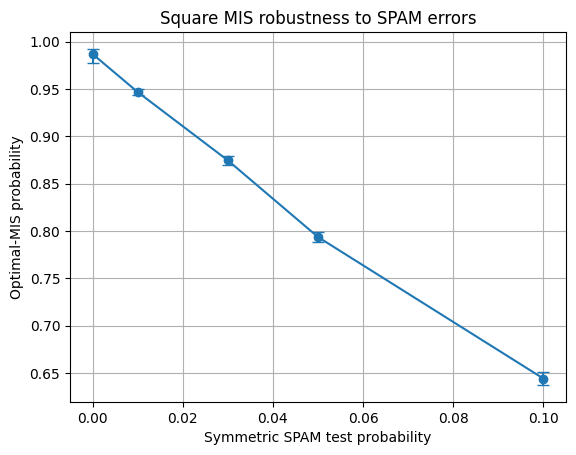

In [52]:
x = [row["error_level"] for row in spam_results]
y = [row["success_probability"] for row in spam_results]
yerr_low = [
    row["success_probability"] - row["ci_low"]
    for row in spam_results
]
yerr_high = [
    row["ci_high"] - row["success_probability"]
    for row in spam_results
]

plt.figure()
plt.errorbar(
    x,
    y,
    yerr=[yerr_low, yerr_high],
    marker="o",
    capsize=4,
)
plt.xlabel("Symmetric SPAM test probability")
plt.ylabel("Optimal-MIS probability")
plt.title("Square MIS robustness to SPAM errors")
plt.grid(True)
plt.show()


### Noise-study result

For the saved run:

```text
dephasing_rate: 0.00 → 0.10 1/µs
P(optimal):     0.983 → 0.767

symmetric SPAM level: 0.00 → 0.10
P(optimal):            0.988 → 0.6153
```

Both sweeps show the expected reduction in optimal-solution probability as the controlled noise level increases. The result is a sensitivity characterization of the tuned square sequence, not a hardware-noise prediction.


<a id="p4-scaling"></a>

## Experiment 4.2 — Path-graph scalability study

The reusable graph pipeline is applied to path graphs:

```text
P4, P5, P6, P7, P8
```

using one fixed pulse schedule:

```text
duration = 3000 ns
final detuning = 6 rad/µs
max amplitude = 2.5 rad/µs
```

For each graph, the notebook records:

- exact classical MIS size;
- optimal-solution probability;
- valid-independent-set probability;
- expected number of selected vertices;
- best valid independent-set size observed;
- local simulation runtime.

The runtime is a property of the local exact simulation environment and is not interpreted as QPU execution time.


In [53]:
def make_path_graph(n_nodes, spacing=6.0):
    coordinates = [
        (i * spacing, 0.0)
        for i in range(n_nodes)
    ]

    edges = [
        (i, i + 1)
        for i in range(n_nodes - 1)
    ]

    return coordinates, edges


def graph_sample_metrics(
    counts,
    edges,
    optimal_bitstrings,
):
    total = sum(counts.values())

    success_count = 0
    valid_count = 0
    weighted_size_sum = 0.0
    best_valid_size = 0

    for bitstring, count in counts.items():
        size = independent_set_size(bitstring)
        weighted_size_sum += count * size

        if bitstring in optimal_bitstrings:
            success_count += count

        if is_valid_independent_set(bitstring, edges):
            valid_count += count
            best_valid_size = max(best_valid_size, size)

    success_probability_value = success_count / total
    valid_probability_value = valid_count / total
    expected_size = weighted_size_sum / total

    ci_low, ci_high = wilson_interval(
        success_count,
        total,
    )

    return {
        "success_probability": success_probability_value,
        "success_ci_low": ci_low,
        "success_ci_high": ci_high,
        "valid_probability": valid_probability_value,
        "expected_selected_vertices": expected_size,
        "best_valid_size_observed": best_valid_size,
        "shots": total,
    }


In [54]:
path_sizes = [4, 5, 6, 7, 8]

path_scaling_results = []

for n_nodes in path_sizes:
    coordinates_n, edges_n = make_path_graph(
        n_nodes=n_nodes,
        spacing=6.0,
    )

    optimal_n, optimal_size_n = find_classical_optimum(
        n_nodes=n_nodes,
        edges=edges_n,
    )

    start = time.perf_counter()

    counts_n, _ = run_pulser_graph(
        coordinates=coordinates_n,
        duration=3000,
        final_detuning=6.0,
        max_amplitude=2.5,
    )

    runtime_seconds = time.perf_counter() - start

    metrics_n = graph_sample_metrics(
        counts=counts_n,
        edges=edges_n,
        optimal_bitstrings=optimal_n,
    )

    row = {
        "n_nodes": n_nodes,
        "classical_optimal_size": optimal_size_n,
        "n_optimal_bitstrings": len(optimal_n),
        "runtime_seconds": runtime_seconds,
        **metrics_n,
    }

    path_scaling_results.append(row)

    print(
        "N =", n_nodes,
        "| MIS size =", optimal_size_n,
        "| P(optimal) =", round(row["success_probability"], 4),
        "| P(valid) =", round(row["valid_probability"], 4),
        "| E[selected] =", round(row["expected_selected_vertices"], 4),
        "| best valid observed =", row["best_valid_size_observed"],
        "| runtime =", round(runtime_seconds, 3), "s",
    )


N = 4 | MIS size = 2 | P(optimal) = 0.837 | P(valid) = 0.998 | E[selected] = 1.838 | best valid observed = 2 | runtime = 0.116 s
N = 5 | MIS size = 3 | P(optimal) = 0.562 | P(valid) = 1.0 | E[selected] = 2.447 | best valid observed = 3 | runtime = 0.109 s
N = 6 | MIS size = 3 | P(optimal) = 0.755 | P(valid) = 0.999 | E[selected] = 2.733 | best valid observed = 3 | runtime = 0.123 s
N = 7 | MIS size = 4 | P(optimal) = 0.397 | P(valid) = 0.998 | E[selected] = 3.224 | best valid observed = 4 | runtime = 0.138 s
N = 8 | MIS size = 4 | P(optimal) = 0.647 | P(valid) = 1.0 | E[selected] = 3.578 | best valid observed = 4 | runtime = 0.181 s


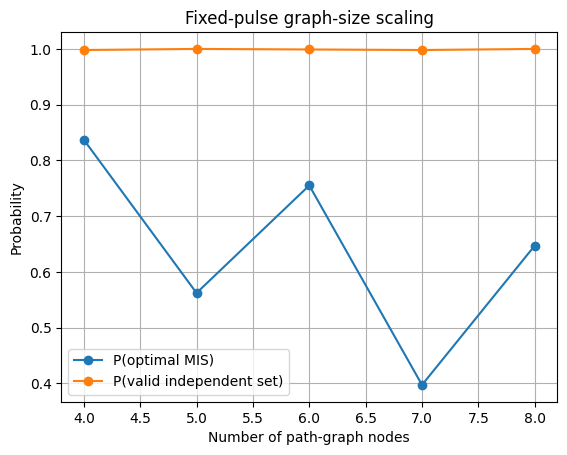

In [55]:
x = [row["n_nodes"] for row in path_scaling_results]

success_y = [
    row["success_probability"]
    for row in path_scaling_results
]

valid_y = [
    row["valid_probability"]
    for row in path_scaling_results
]

plt.figure()
plt.plot(
    x,
    success_y,
    marker="o",
    label="P(optimal MIS)",
)
plt.plot(
    x,
    valid_y,
    marker="o",
    label="P(valid independent set)",
)
plt.xlabel("Number of path-graph nodes")
plt.ylabel("Probability")
plt.title("Fixed-pulse graph-size scaling")
plt.legend()
plt.grid(True)
plt.show()


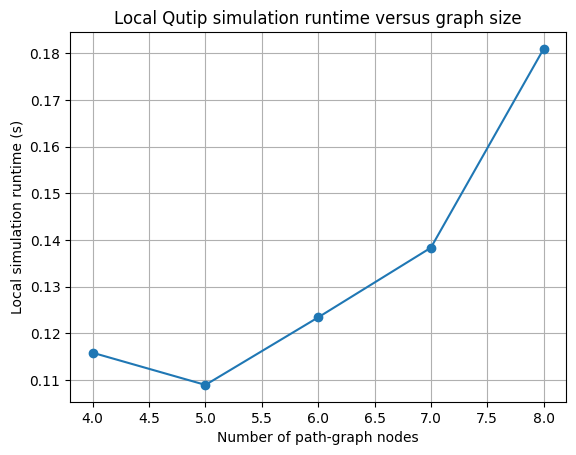

In [56]:
runtime_y = [
    row["runtime_seconds"]
    for row in path_scaling_results
]

plt.figure()
plt.plot(
    x,
    runtime_y,
    marker="o",
)
plt.xlabel("Number of path-graph nodes")
plt.ylabel("Local simulation runtime (s)")
plt.title("Local Qutip simulation runtime versus graph size")
plt.grid(True)
plt.show()


### Scaling-study interpretation

This is a fixed-schedule transfer study rather than a per-size optimization study.

Across `P4`–`P8`, the valid-independent-set probability remains approximately `0.999–1.000`, and the exact MIS size is observed for every tested graph. The optimal-solution probability varies non-monotonically with graph size because the same pulse schedule is reused without retuning.

A separate per-size pulse optimization would answer a different question and is intentionally outside this benchmark.


<a id="p4-mwis"></a>

## Experiment 4.3 — Weighted MIS with local detuning

The unweighted MIS formulation is extended to:

\[
\max \sum_i w_i x_i
\]

subject to the same independent-set constraints.

For the square graph, the selected node weights are:

```text
[1.00, 0.35, 0.45, 0.95]
```

The two diagonal independent sets are `1001` and `0110`, but the weighting makes:

```text
1001
```

the unique classical MWIS solution with total weight:

```text
1.95
```

### Neutral-atom encoding

The geometry supplies the Rydberg interaction / independent-set constraint structure, while a Detuning Map Modulator (DMM) applies local site-dependent detuning weights.

`MockDevice` is used for this experiment because it exposes both a global Rydberg channel and a DMM for local prototyping.


In [57]:
def find_classical_weighted_optimum(
    n_nodes,
    edges,
    node_weights,
):
    best_weight = -np.inf
    best_bitstrings = set()

    for bitstring in all_bitstrings(n_nodes):
        if not is_valid_independent_set(
            bitstring,
            edges,
        ):
            continue

        score = sum(
            node_weights[i]
            for i, bit in enumerate(bitstring)
            if bit == "1"
        )

        if score > best_weight + 1e-12:
            best_weight = score
            best_bitstrings = {bitstring}

        elif np.isclose(
            score,
            best_weight,
        ):
            best_bitstrings.add(bitstring)

    return best_bitstrings, float(best_weight)


weighted_node_weights = np.array([
    1.00,
    0.35,
    0.45,
    0.95,
])

weighted_optimal_bitstrings, weighted_optimal_value = (
    find_classical_weighted_optimum(
        n_nodes=len(square_coordinates),
        edges=square_edges,
        node_weights=weighted_node_weights,
    )
)

print("Node weights:", weighted_node_weights)
print("Classical weighted optimum:", weighted_optimal_value)
print(
    "Classical weighted-optimal bitstrings:",
    sorted(weighted_optimal_bitstrings),
)


def final_mwis_energy_table(
    node_weights,
    omega_scale=10.0,
):
    """
    Evaluate the diagonal (Omega=0) final Hamiltonian energy
    for every computational-basis bitstring.

    Used to verify the final computational-basis energy ordering before QAA sampling.
    """

    device = pulser.MockDevice
    C6 = device.interaction_coeff

    edge_set = {
        tuple(sorted(edge))
        for edge in square_edges
    }

    non_edge_distances = []

    for i in range(len(square_coordinates)):
        for j in range(i):
            if tuple(sorted((i, j))) not in edge_set:
                xi, yi = square_coordinates[i]
                xj, yj = square_coordinates[j]
                non_edge_distances.append(
                    np.sqrt(
                        (xi - xj) ** 2
                        + (yi - yj) ** 2
                    )
                )

    V_non_edge_max = (
        C6 / min(non_edge_distances) ** 6
    )

    delta_f = (
        omega_scale
        * V_non_edge_max
    )

    normalized_weights = (
        node_weights
        / np.max(node_weights)
    )

    # With delta_DMM = -delta_f and epsilon_i = 1-w_i/w_max:
    # Delta_i(final) = delta_f * w_i / w_max
    local_final_detunings = (
        delta_f
        * normalized_weights
    )

    rows = []

    for bitstring in all_bitstrings(
        len(square_coordinates)
    ):
        occupied = [
            i
            for i, bit in enumerate(bitstring)
            if bit == "1"
        ]

        energy = -sum(
            local_final_detunings[i]
            for i in occupied
        )

        for a in range(len(occupied)):
            for b in range(a):
                i = occupied[a]
                j = occupied[b]

                xi, yi = square_coordinates[i]
                xj, yj = square_coordinates[j]

                distance = np.sqrt(
                    (xi - xj) ** 2
                    + (yi - yj) ** 2
                )

                energy += (
                    C6
                    / distance**6
                )

        rows.append(
            (bitstring, float(energy))
        )

    rows.sort(
        key=lambda item: item[1]
    )

    return rows


energy_rows = final_mwis_energy_table(
    weighted_node_weights
)

print("\nLowest final diagonal energies:")
for bitstring, energy in energy_rows[:6]:
    print(
        bitstring,
        "->",
        round(energy, 4),
        "rad/µs",
    )

print(
    "\nFinal-Hamiltonian ground-state candidate:",
    energy_rows[0][0],
)


Node weights: [1.   0.35 0.45 0.95]
Classical weighted optimum: 1.95
Classical weighted-optimal bitstrings: ['1001']

Lowest final diagonal energies:
1001 -> -268.6496 rad/µs
1000 -> -145.216 rad/µs
0001 -> -137.9552 rad/µs
1011 -> -101.6512 rad/µs
0110 -> -101.6512 rad/µs
1010 -> -94.3904 rad/µs

Final-Hamiltonian ground-state candidate: 1001


In [58]:
def build_weighted_square_sequence(
    node_weights,
    use_dmm=True,
    duration=40000,
    omega_scale=10.0,
):
    """
    Build the weighted-square QAA sequence.

    The pulse scale follows the heuristic used in the Pulser MWIS tutorial:

        Omega_max = 10 * max interaction between non-connected nodes
        delta_0   = -Omega_max
        delta_f   = +Omega_max

    The DMM then reduces the positive final detuning of lower-weight
    vertices, leaving the highest-weight vertex unpenalized.
    """

    weighted_device = pulser.MockDevice

    reg = pulser.Register.from_coordinates(
        square_coordinates,
        prefix="q",
    )

    seq = pulser.Sequence(
        reg,
        weighted_device,
    )

    seq.declare_channel(
        "rydberg_global",
        "rydberg_global",
    )

    interaction_coeff = weighted_device.interaction_coeff

    edge_set = {
        tuple(sorted(edge))
        for edge in square_edges
    }

    non_connected_distances = []

    for i in range(len(square_coordinates)):
        for j in range(i):
            pair = tuple(sorted((i, j)))

            if pair not in edge_set:
                xi, yi = square_coordinates[i]
                xj, yj = square_coordinates[j]

                distance = float(
                    np.sqrt(
                        (xi - xj) ** 2
                        + (yi - yj) ** 2
                    )
                )

                non_connected_distances.append(distance)

    min_non_connected_distance = min(
        non_connected_distances
    )

    max_non_edge_interaction = (
        interaction_coeff
        / min_non_connected_distance**6
    )

    omega = (
        omega_scale
        * max_non_edge_interaction
    )

    delta_0 = -omega
    delta_f = omega

    print("MWIS QAA parameters:")
    print(
        "  max non-edge interaction =",
        round(max_non_edge_interaction, 4),
        "rad/µs",
    )
    print(
        "  Omega_max                =",
        round(omega, 4),
        "rad/µs",
    )
    print(
        "  delta_0                  =",
        round(delta_0, 4),
        "rad/µs",
    )
    print(
        "  delta_f                  =",
        round(delta_f, 4),
        "rad/µs",
    )
    print(
        "  duration                 =",
        duration,
        "ns",
    )

    amplitude = pulser.InterpolatedWaveform(
        duration,
        [
            1e-9,
            omega,
            1e-9,
        ],
    )

    detuning = pulser.InterpolatedWaveform(
        duration,
        [
            delta_0,
            0.0,
            delta_f,
        ],
    )

    adiabatic_pulse = pulser.Pulse(
        amplitude=amplitude,
        detuning=detuning,
        phase=0.0,
    )

    seq.add(
        adiabatic_pulse,
        "rydberg_global",
    )

    if use_dmm:
        normalized_weights = (
            node_weights
            / np.max(node_weights)
        )

        detuning_map_weights = (
            1.0
            - normalized_weights
        )

        detuning_map = reg.define_detuning_map({
            f"q{i}": float(detuning_map_weights[i])
            for i in range(len(node_weights))
        })

        seq.config_detuning_map(
            detuning_map,
            "dmm_0",
        )

        # This overlaps the global pulse: add_dmm_detuning uses
        # the DMM channel's independent timeline.
        seq.add_dmm_detuning(
            pulser.ConstantWaveform(
                duration,
                -delta_f,
            ),
            "dmm_0",
        )

    seq.measure("ground-rydberg")

    return seq


### DMM comparison

The same square geometry and global QAA pulse are simulated with and without local DMM weighting.

Without DMM, the ideal square geometry is symmetric between the two diagonal MIS states. With DMM, the site-dependent detuning breaks this degeneracy in favour of the higher-weight diagonal.

The QAA pulse follows the heuristic used in the Pulser MWIS example:

```text
Omega_max = 10 × maximum non-edge interaction
delta_0   = -Omega_max
delta_f   = +Omega_max
duration  = 40 µs
```

Before sampling, the final diagonal Hamiltonian is evaluated directly. The computed lowest-energy computational-basis state is `1001`, consistent with the exact classical weighted optimum.


In [59]:
unweighted_reference_sequence = build_weighted_square_sequence(
    node_weights=weighted_node_weights,
    use_dmm=False,
)

weighted_dmm_sequence = build_weighted_square_sequence(
    node_weights=weighted_node_weights,
    use_dmm=True,
)

unweighted_reference_counts = (
    QutipBackendV2(
        unweighted_reference_sequence
    )
    .run()
    .final_bitstrings
)

weighted_dmm_counts = (
    QutipBackendV2(
        weighted_dmm_sequence
    )
    .run()
    .final_bitstrings
)

p_weighted_opt_no_dmm, low_no_dmm, high_no_dmm = (
    target_probability_with_ci(
        unweighted_reference_counts,
        weighted_optimal_bitstrings,
    )
)

p_weighted_opt_dmm, low_dmm, high_dmm = (
    target_probability_with_ci(
        weighted_dmm_counts,
        weighted_optimal_bitstrings,
    )
)

print("Weighted-optimum probability without DMM:")
print(
    round(p_weighted_opt_no_dmm, 4),
    "| 95% CI =",
    (round(low_no_dmm, 4), round(high_no_dmm, 4)),
)

print("\nWeighted-optimum probability with DMM:")
print(
    round(p_weighted_opt_dmm, 4),
    "| 95% CI =",
    (round(low_dmm, 4), round(high_dmm, 4)),
)

print("\nTop outcomes without DMM:")
print(unweighted_reference_counts.most_common(10))

print("\nTop outcomes with DMM:")
print(weighted_dmm_counts.most_common(10))


MWIS QAA parameters:
  max non-edge interaction = 14.5216 rad/µs
  Omega_max                = 145.216 rad/µs
  delta_0                  = -145.216 rad/µs
  delta_f                  = 145.216 rad/µs
  duration                 = 40000 ns
MWIS QAA parameters:
  max non-edge interaction = 14.5216 rad/µs
  Omega_max                = 145.216 rad/µs
  delta_0                  = -145.216 rad/µs
  delta_f                  = 145.216 rad/µs
  duration                 = 40000 ns
Weighted-optimum probability without DMM:
0.522 | 95% CI = (0.491, 0.5528)

Weighted-optimum probability with DMM:
1.0 | 95% CI = (0.9962, 1.0)

Top outcomes without DMM:
[('1001', 522), ('0110', 478)]

Top outcomes with DMM:
[('1001', 1000)]


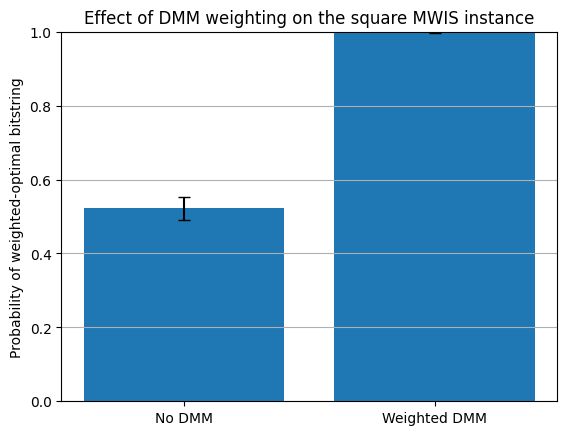

In [60]:
labels = [
    "No DMM",
    "Weighted DMM",
]

values = [
    p_weighted_opt_no_dmm,
    p_weighted_opt_dmm,
]

lower_errors = [
    p_weighted_opt_no_dmm - low_no_dmm,
    p_weighted_opt_dmm - low_dmm,
]

upper_errors = [
    high_no_dmm - p_weighted_opt_no_dmm,
    high_dmm - p_weighted_opt_dmm,
]

plt.figure()
plt.bar(
    labels,
    values,
    yerr=[lower_errors, upper_errors],
    capsize=4,
)
plt.ylabel("Probability of weighted-optimal bitstring")
plt.title("Effect of DMM weighting on the square MWIS instance")
plt.ylim(0.0, 1.0)
plt.grid(axis="y")
plt.show()


## Part 4 summary

The three extended studies produce the following results.

### Noise robustness

Controlled dephasing and SPAM perturbations reduce the optimal-solution probability of the tuned square graph, providing a direct sensitivity curve for the simulated pulse sequence.

### Fixed-schedule graph scaling

For path graphs `P4`–`P8`, the sampled states remain almost entirely valid independent sets and the exact MIS size is observed in every tested case, although the probability of sampling an exact optimum varies with graph size.

### Weighted neutral-atom optimization

For the MWIS weights `[1.00, 0.35, 0.45, 0.95]`, the exact classical optimum is `1001` with weight `1.95`.

Without DMM weighting, the two geometrically equivalent diagonal states split the sampled probability approximately evenly:

```text
P(1001) = 0.477
P(0110) = 0.523
```

With DMM weighting, all 1000 sampled shots return `1001`:

```text
observed P(1001) = 1.000
95% Wilson interval = [0.9962, 1.000]
```

This demonstrates that local detuning can resolve a geometric MIS degeneracy according to a linear vertex-weight objective. It does not imply that an arbitrary quadratic MIMO objective can be encoded exactly by the same mechanism.


---

# Overall conclusion

The notebook establishes a complete simulation workflow for Pasqal/Pulser:

```text
pulse-level neutral-atom control
→ geometry-dependent blockade
→ graph optimization
→ exact classical validation
→ communication-inspired candidate generation
→ controlled noise sensitivity
→ graph-size transfer
→ weighted MIS through local detuning
```

The strongest neutral-atom-specific result is the MWIS experiment, where DMM weighting changes the unique weighted optimum `1001` from an approximately 50% member of a symmetric unweighted pair to the sole observed outcome in 1000 simulated shots.

The MIMO experiments remain deliberately separated from this claim: their full communication objective is evaluated classically, while Pulser is used only for constraint-aware candidate generation. This distinction is maintained throughout the notebook.
